## EDA Notebook - CGMacros Dataset

In [1]:
import os
import glob
import numpy as np
import pandas as pd
from scipy.stats import zscore

#visualization libs
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

#statistics libs
from scipy.stats import ttest_ind, mannwhitneyu, kruskal
from scipy.stats import pearsonr, spearmanr

In [2]:
# Display settings
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.2f}'.format) 

# Plot styling to keep all plots consistent
plt.rcParams.update({
    'figure.figsize':  (10, 6),
    'axes.titlesize':  14,
    'axes.labelsize':  12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi':      100
})

# Color palette for health groups 
HEALTH_COLORS = {
    'Healthy': '#4CAF50',   # green'
    'PreD':    '#2196F3',   # blue
    'T2D':     '#F44336'    # red
}

# Path to data 
DATA_PATH = r"C:\Users\Laura\OneDrive\Desktop\cgmacro-dataset\CGMacros_dateshifted365\CGMacros"

### Helper Functions

In [3]:
def classify_health(a1c):
    """Classify subject health status based on A1c value"""
    if a1c < 5.7:
        return 'Healthy'
    elif a1c <= 6.4:
        return 'PreD' #prediabetic
    else:
        return 'T2D' #type2 diabetes

### Load All Data Sources

In [4]:
bio_path = os.path.join(DATA_PATH, "bio.csv")
bio_df = pd.read_csv(bio_path)
print(f"bio.csv loaded: {bio_df.shape[0]} subjects, "
      f"{bio_df.shape[1]} columns")

# Clean column names first (several have trailing spaces)
bio_df.columns = bio_df.columns.str.strip()

# Check columns to observe features
print(bio_df.columns)

bio.csv loaded: 45 subjects, 24 columns
Index(['subject', 'Age', 'Gender', 'BMI', 'Body weight', 'Height',
       'Self-identify', 'A1c PDL (Lab)', 'Fasting GLU - PDL (Lab)', 'Insulin',
       'Triglycerides', 'Cholesterol', 'HDL', 'Non HDL', 'LDL (Cal)',
       'VLDL (Cal)', 'Cho/HDL Ratio', 'Collection time PDL (Lab)',
       '#1 Contour Fingerstick GLU', 'Time (t)', '#2 Contour Fingerstick GLU',
       'Time (t).1', '#3 Contour Fingerstick GLU', 'Time (t).2'],
      dtype='str')


In [5]:
# Check for column types and missing values
print("COLUMN TYPES & MISSING VALUES")
summary = pd.DataFrame({
    'dtype':   bio_df.dtypes,
    'missing': bio_df.isnull().sum(),
    'sample':  bio_df.iloc[0]
})
print(summary.to_string())

COLUMN TYPES & MISSING VALUES
                              dtype  missing           sample
subject                       int64        0                1
Age                           int64        0               27
Gender                          str        0                M
BMI                         float64        0            22.27
Body weight                 float64        0           133.80
Height                      float64        0            65.00
Self-identify                   str        0  Hispanic/Latino
A1c PDL (Lab)               float64        0             5.40
Fasting GLU - PDL (Lab)       int64        0               91
Insulin                     float64        0             2.50
Triglycerides                 int64        0               67
Cholesterol                   int64        0              216
HDL                           int64        0               74
Non HDL                       int64        0              142
LDL (Cal)                     int64     

In [6]:
# 1. Fix subject ID to match the ones from the meals (001, 002, etc.)
bio_df['subject'] = bio_df['subject'].astype(str).str.zfill(3)

# 2. Classify health groups from A1c
bio_df['Health_group'] = bio_df['A1c PDL (Lab)'].apply(classify_health)

print("Health group distribution:")
print(bio_df['Health_group'].value_counts().to_string())

Health group distribution:
Health_group
PreD       16
Healthy    15
T2D        14


In [7]:
# 3. Calculate HOMA-IR (insulin resistance index)

# Formula: HOMA-IR = (fasting insulin × fasting glucose) / 405
# Insulin in uIU/mL, glucose in mg/dL
bio_df['HOMA_IR'] = (bio_df['Insulin'] * bio_df['Fasting GLU - PDL (Lab)']) / 405

In [8]:
# 4. Decide which columns to keep 
KEEP_COLS = [
    'subject',
    'Health_group',       # derived - primary grouping variable
    'Age',
    'Gender',
    'BMI',
    'A1c PDL (Lab)',      # renamed below
    'Fasting GLU - PDL (Lab)',
    'Insulin',
    'HOMA_IR',            # derived
    'Triglycerides',
    'Cholesterol',
    'HDL',
    'Non HDL',
    'LDL (Cal)',
    'VLDL (Cal)',
    'Cho/HDL Ratio',
]

bio_clean = bio_df[KEEP_COLS].rename(columns={
    'A1c PDL (Lab)':           'A1c',
    'Fasting GLU - PDL (Lab)': 'Fasting_glucose',
    'LDL (Cal)':               'LDL',
    'VLDL (Cal)':              'VLDL',
    'Cho/HDL Ratio':           'Cho_HDL_ratio',
    'Non HDL':                 'Non_HDL',
})

print(f"\nbio_clean shape: {bio_clean.shape}")
print(bio_clean.head(3).to_string())


bio_clean shape: (45, 16)
  subject Health_group  Age Gender   BMI  A1c  Fasting_glucose  Insulin  HOMA_IR  Triglycerides  Cholesterol  HDL  Non_HDL  LDL  VLDL  Cho_HDL_ratio
0     001      Healthy   27      M 22.27 5.40               91     2.50     0.56             67          216   74      142  130    13           2.90
1     002      Healthy   49      F 30.95 5.50               93    14.80     3.40             61          181   91       90   78    12           2.00
2     003          T2D   59      F 26.95 6.50              118    17.40     5.07            154          190   74      116   90    31           2.60


In [9]:
microbes_path = os.path.join(DATA_PATH,"microbes.csv")
microbes_df = pd.read_csv(microbes_path)
print(f"microbes.csv loaded: {microbes_df.shape[0]} subjects, "
      f"{microbes_df.shape[1]} bacteria features")

microbes.csv loaded: 45 subjects, 1980 bacteria features


In [10]:
gut_path = os.path.join(DATA_PATH,"gut_health_test.csv")
gut_df = pd.read_csv(gut_path)
print(f"gut_health_test.csv loaded: {gut_df.shape[0]} subjects, "
      f"{gut_df.shape[1]} columns")

gut_df.columns = gut_df.columns.str.strip()
gut_df['subject'] = gut_df['subject'].astype(str).str.zfill(3)

# gut health data has 2 extra subjects included (024, 025)
# Data Completely missing for subjects 026, 028, 048 - will not include in EDA and experiments for now !!!

gut_health_test.csv loaded: 47 subjects, 23 columns


In [10]:
from scipy.integrate import trapezoid

def calc_iauc(cgm, sampling_interval=15):
    """Calculate incremental AUC above baseline"""
    a = [i * sampling_interval for i in range(len(cgm))]
    total = 0
    for i in range(len(cgm) - 1):
        b0 = cgm[i]   - cgm[0]
        b1 = cgm[i+1] - cgm[0]
        if b1 >= 0 and b0 >= 0:
            total += ((b0 + b1) / 2) * sampling_interval
        elif b1 < 0 and b0 >= 0:
            total += (b0 * (b0 / (b0 - b1)) * sampling_interval / 2)
        elif b1 >= 0 and b0 < 0:
            total += (b1 * (b1 / (b1 - b0)) * sampling_interval / 2)
    return total

def calc_auc(cgm, sampling_interval=15):
    """Calculate total AUC using trapezoid rule"""
    return trapezoid(cgm, dx=sampling_interval)

In [102]:
# DATASET SCHEMA AUDIT - automatic discovery of data inconsistencies across the csv's about the meals and CGMs data for each subject of the study

import os
import pandas as pd
from collections import defaultdict

audit = {}   # subject -> {cols, meal_types, col_order}

for sub_folder in sorted(os.listdir(DATA_PATH)):
    if not sub_folder.startswith("CGMacros"):
        continue
    csv_path = os.path.join(DATA_PATH, sub_folder, sub_folder + ".csv")
    if not os.path.exists(csv_path):
        audit[sub_folder] = {"error": "CSV file not found"}
        continue

    df = pd.read_csv(csv_path, nrows=0)
    cols = df.columns.str.strip().tolist()
    cols = [c for c in cols if not c.startswith("Unnamed")]  # drop index artifacts

    # Also grab unique meal type labels
    meal_col_df = pd.read_csv(csv_path, usecols=lambda c: c.strip() == "Meal Type")
    meal_col_df.columns = meal_col_df.columns.str.strip()
    meal_types = sorted(meal_col_df["Meal Type"].dropna().str.strip().unique().tolist())

    audit[sub_folder] = {"cols": cols, "meal_types": meal_types}

# 1. Derive the majority schema (what most subjects have as features) 
from collections import Counter

all_col_lists   = [tuple(v["cols"]) for v in audit.values() if "cols" in v]
majority_schema = Counter(all_col_lists).most_common(1)[0][0]
majority_col_set = set(majority_schema)

print("MAJORITY SCHEMA  (most common across all subjects)")
print(" | ".join(majority_schema))

# 2. Per-subject column deviations
print("PER-SUBJECT DEVIATIONS FROM MAJORITY SCHEMA")

deviations_found = False
for sub, info in audit.items():
    if "error" in info:
        print(f"\n[{sub}] {info['error']}")
        deviations_found = True
        continue

    sub_cols    = info["cols"]
    sub_col_set = set(sub_cols)

    missing_cols = majority_col_set - sub_col_set
    extra_cols   = sub_col_set - majority_col_set
    order_diff   = (sub_cols != list(majority_schema) and
                    not missing_cols and not extra_cols)

    issues = []
    if missing_cols:
        issues.append(f"  MISSING cols : {sorted(missing_cols)}")
    if extra_cols:
        issues.append(f"  EXTRA cols   : {sorted(extra_cols)}")
    if order_diff:
        issues.append(f"  WRONG ORDER  : {sub_cols}")
        issues.append(f"  expected     : {list(majority_schema)}")

    if issues:
        deviations_found = True
        print(f"\n[{sub}]")
        for i in issues:
            print(i)

if not deviations_found:
    print("  No column deviations found ✓")

# 3. Meal type label variants across all subjects 
print("MEAL TYPE LABELS — all unique values found")

all_meal_labels = defaultdict(list)
for sub, info in audit.items():
    if "meal_types" not in info:
        continue
    for label in info["meal_types"]:
        all_meal_labels[label].append(sub)

for label, subjects in sorted(all_meal_labels.items()):
    print(f"  '{label}' -> {len(subjects)} subject(s): {subjects}")

# 4. Column-level presence summary (which cols are not universal) 
print("COLUMN PRESENCE SUMMARY  (non-universal columns only)")

total = sum(1 for v in audit.values() if "cols" in v)
col_presence = defaultdict(list)
for sub, info in audit.items():
    if "cols" not in info:
        continue
    for c in info["cols"]:
        col_presence[c].append(sub)

for col, subjects in sorted(col_presence.items(), key=lambda x: len(x[1])):
    if len(subjects) < total:
        print(f"  '{col}': {len(subjects)}/{total} subjects "
              f"-> MISSING from: {sorted(set(audit) - set(subjects) - {s for s in audit if 'error' in audit[s]})}")

MAJORITY SCHEMA  (most common across all subjects)
Timestamp | Libre GL | Dexcom GL | HR | Calories (Activity) | METs | Meal Type | Calories | Carbs | Protein | Fat | Fiber | Amount Consumed | Image path
PER-SUBJECT DEVIATIONS FROM MAJORITY SCHEMA

[CGMacros-004]
  WRONG ORDER  : ['Timestamp', 'Dexcom GL', 'Libre GL', 'HR', 'Calories (Activity)', 'METs', 'Meal Type', 'Calories', 'Carbs', 'Protein', 'Fat', 'Fiber', 'Amount Consumed', 'Image path']
  expected     : ['Timestamp', 'Libre GL', 'Dexcom GL', 'HR', 'Calories (Activity)', 'METs', 'Meal Type', 'Calories', 'Carbs', 'Protein', 'Fat', 'Fiber', 'Amount Consumed', 'Image path']

[CGMacros-007]
  MISSING cols : ['Calories (Activity)']
  EXTRA cols   : ['RecordIndex', 'Steps']

[CGMacros-011]
  MISSING cols : ['METs']
  EXTRA cols   : ['Intensity']

[CGMacros-013]
  EXTRA cols   : ['Sugar']

[CGMacros-026]
  MISSING cols : ['METs']
  EXTRA cols   : ['Intensity']

[CGMacros-027]
  MISSING cols : ['METs']
  EXTRA cols   : ['Intensity']



In [11]:
def get_col(data, col, default=np.nan):
    """Return column if it exists, else a NaN series."""
    if col in data.columns:
        return data[col]
    return pd.Series([default] * len(data), index=data.index)

# Canonical meal type mapping - covers case variants and label variants discovered in the previous audit 
MEAL_TYPE_MAP = {
    'breakfast': 'Breakfast',
    'lunch':     'Lunch',
    'dinner':    'Dinner',
    'snack':     'Snack',
    'snacks':    'Snack',   # plural variant
    'snack 1':   'Snack',   # numbered variant (CGMacros-009)
}


In [12]:
all_meals = []

for sub_folder in sorted(os.listdir(DATA_PATH)):
    if not sub_folder.startswith("CGMacros"):
        continue

    csv_path = os.path.join(DATA_PATH, sub_folder, sub_folder + '.csv')
    if not os.path.exists(csv_path):
        print(f"Missing CSV for {sub_folder}")
        continue

    data = pd.read_csv(csv_path)
    data.columns = data.columns.str.strip()
    sub_id = sub_folder[-3:]

    meal_mask = data["Meal Type"].notna()

    for idx in data[meal_mask].index:

        raw_label = str(data["Meal Type"][idx]).strip().lower()
        meal_type = MEAL_TYPE_MAP.get(raw_label, raw_label.capitalize())

        libre_trace  = get_col(data, "Libre GL")[idx:idx+135:15].tolist()
        dexcom_trace = get_col(data, "Dexcom GL")[idx:idx+121:5].tolist()

        if len(libre_trace) < 9:
            continue

        libre_clean  = [x for x in libre_trace  if pd.notna(x)]
        dexcom_clean = [x for x in dexcom_trace if pd.notna(x)]

        iauc_libre = calc_iauc(libre_clean)
        auc_libre  = calc_auc(libre_clean)

        if len(dexcom_clean) == 25:
            iauc_dexcom     = calc_iauc(dexcom_clean)
            auc_dexcom      = calc_auc(dexcom_clean)
            dexcom_complete = True
        else:
            iauc_dexcom     = np.nan
            auc_dexcom      = np.nan
            dexcom_complete = False
        
        # Activity windows — mean cal/min (robust to partial windows)
        pre_start   = max(0, idx - 60)
        pre_window  = get_col(data, "Calories (Activity)")[pre_start:idx].dropna().tolist()
        post_window = get_col(data, "Calories (Activity)")[idx:idx+121].dropna().tolist()

        meal = {
            'subject':          sub_id,
            'Meal_Type':        meal_type,
            'Timestamp':        data["Timestamp"][idx],

            'Libre_trace':      libre_trace,
            'Baseline_Libre':   libre_trace[0],
            'iAUC_libre':       iauc_libre,
            'AUC_libre':        auc_libre,

            'Dexcom_trace':     dexcom_trace,
            'Baseline_Dexcom':  dexcom_trace[0] if dexcom_trace else np.nan,
            'iAUC_dexcom':      iauc_dexcom,
            'AUC_dexcom':       auc_dexcom,
            'dexcom_complete':  dexcom_complete,

            'Calories':         get_col(data, "Calories")[idx],
            'Carbs_g':          get_col(data, "Carbs")[idx],
            'Protein_g':        get_col(data, "Protein")[idx],
            'Fat_g':            get_col(data, "Fat")[idx],
            'Fiber_g':          get_col(data, "Fiber")[idx],
            'Activity_pre_sum':      sum(pre_window)  if pre_window  else np.nan,
            'Activity_post_sum':     sum(post_window) if post_window else np.nan,
            'Activity_pre_coverage':  len(pre_window) / 60,
            'Activity_post_coverage': len(post_window) / 121,
        }
        all_meals.append(meal)

# MAIN DATAFRAME WITH COMPLETE MEALS DATA 
meals_df = pd.DataFrame(all_meals)
meals_df = meals_df[meals_df['iAUC_libre'] > 0].reset_index(drop=True)

# Impute remaining missing values 
meals_df['Fiber_g']      = meals_df['Fiber_g'].fillna(0)

# Merge clinical features from bio_clean
meals_df = meals_df.merge(bio_clean, on='subject', how='left')

# Split into working dataframes 
meals_libre_df  = meals_df.copy()
meals_dexcom_df = meals_df[meals_df['dexcom_complete']].reset_index(drop=True)

# Final summary
print(f"meals_libre_df  : {len(meals_libre_df)} meals, "
      f"{meals_libre_df['subject'].nunique()} subjects, "
      f"{meals_libre_df.shape[1]} columns")
print(f"meals_dexcom_df : {len(meals_dexcom_df)} meals, "
      f"{meals_dexcom_df['subject'].nunique()} subjects")

print(f"\nHealth group distribution (subjects):")
print(bio_clean['Health_group'].value_counts().to_string())

print(f"\nHealth group × Meal type (meals_libre_df):")
print(meals_libre_df.groupby(['Health_group', 'Meal_Type'])
                     .size()
                     .unstack(fill_value=0)
                     .to_string())

print(f"\nHealth group × Meal type (meals_dexcom_df):")
print(meals_dexcom_df.groupby(['Health_group', 'Meal_Type'])
                     .size()
                     .unstack(fill_value=0)
                     .to_string())

print(f"\nRemaining missing values:")
missing = meals_dexcom_df.drop(columns=['Libre_trace','Dexcom_trace',
                                        'dexcom_complete']).isnull().sum()
missing = missing[missing > 0]
print("None " if missing.empty else missing.to_string())

meals_dexcom_df

meals_libre_df  : 1557 meals, 45 subjects, 36 columns
meals_dexcom_df : 1523 meals, 45 subjects

Health group distribution (subjects):
Health_group
PreD       16
Healthy    15
T2D        14

Health group × Meal type (meals_libre_df):
Meal_Type     Breakfast  Dinner  Lunch  Snack
Health_group                                 
Healthy             141     170    135    127
PreD                151     166    136    123
T2D                 131     115    109     53

Health group × Meal type (meals_dexcom_df):
Meal_Type     Breakfast  Dinner  Lunch  Snack
Health_group                                 
Healthy             134     170    135    127
PreD                139     163    134    123
T2D                 121     115    109     53

Remaining missing values:
Activity_pre_sum     20
Activity_post_sum    20


,subject,Meal_Type,Timestamp,Libre_trace,Baseline_Libre,iAUC_libre,AUC_libre,Dexcom_trace,Baseline_Dexcom,iAUC_dexcom,AUC_dexcom,dexcom_complete,Calories,Carbs_g,Protein_g,...,Health_group,Age,Gender,BMI,A1c,Fasting_glucose,Insulin,HOMA_IR,Triglycerides,Cholesterol,HDL,Non_HDL,LDL,VLDL,Cho_HDL_ratio
0,001,Lunch,2020-05-01 14:23:00,"[69.8, 68.06666666666666, 74.86666666666666, 8...",69.80,1496.31,9856.00,"[109.4, 113.8, 114.2, 112.4, 115.2, 116.8, 117...",109.40,2318.22,41580.00,True,1170.00,85.00,88.00,...,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
1,001,Dinner,2020-05-01 20:48:00,"[84.8, 96.2, 113.2, 110.6, 96.4, 94.2, 94.4, 9...",84.80,1617.00,11793.00,"[114.8, 114.2, 114.0, 118.0, 115.8, 132.6, 146...",114.80,4265.70,45577.50,True,80.00,18.00,0.00,...,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
2,001,Snack,2020-05-02 00:15:00,"[81.0, 86.0, 107.0, 113.0, 96.0, 90.0, 95.0, 8...",81.00,1650.00,11370.00,"[97.4, 99.8, 103.4, 105.4, 108.2, 114.6, 122.6...",97.40,5580.00,40644.00,True,110.00,24.00,0.00,...,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
3,001,Breakfast,2020-05-02 08:18:00,"[88.4, 98.0, 114.8, 114.0, 96.8, 93.8, 100.4, ...",88.40,1348.51,11848.50,"[101.8, 99.4, 95.8, 95.8, 101.6, 116.6, 127.2,...",101.80,3760.20,39508.50,True,448.00,66.00,22.00,...,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
4,001,Lunch,2020-05-02 12:00:00,"[82.0, 88.0, 103.0, 97.0, 76.0, 75.0, 92.0, 98...",82.00,1039.47,10747.50,"[80.0, 85.4, 92.2, 97.8, 102.4, 109.2, 115.0, ...",80.00,5656.05,31639.50,True,840.00,89.00,17.00,...,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1518,049,Breakfast,2025-05-19 07:06:00,"[132.6, 162.46666666666667, 214.66666666666663...",132.60,13412.50,29324.50,"[164.8, 164.0, 167.0, 175.6, 186.6, 199.4, 214...",164.80,38481.10,97801.50,True,712.00,66.00,22.00,...,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40
1519,049,Lunch,2025-05-19 13:37:00,"[82.93333333333334, 90.46666666666668, 108.733...",82.93,5520.50,15472.50,"[94.8, 95.8, 96.8, 98.6, 102.2, 106.2, 112.6, ...",94.80,18828.00,52956.00,True,445.00,43.00,20.00,...,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40
1520,049,Dinner,2025-05-19 20:21:00,"[88.46666666666667, 108.06666666666666, 148.26...",88.47,8825.50,19441.50,"[106.0, 107.8, 112.0, 115.8, 124.8, 136.6, 157...",106.00,32439.00,70599.00,True,370.00,38.00,26.00,...,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40
1521,049,Breakfast,2025-05-20 07:06:00,"[138.33333333333334, 162.4, 199.8, 225.8, 221....",138.33,5922.50,22522.50,"[152.6, 149.8, 156.2, 168.8, 180.0, 190.0, 201...",152.60,18388.69,73294.50,True,268.00,24.00,22.00,...,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40


In [151]:
# Quality filters 

# Filter 1: Libre sensor floor — unreliable readings
floor_mask = meals_df['Libre_trace'].apply(
    lambda t: any(x <= 40.0 for x in t))

# Filter 2: Zero calories — meal tagged but nothing logged
zero_cal_mask = meals_df['Calories'] == 0

# Filter 3: Any macronutrient out of valid range (0-176g)
macro_mask = (
    (meals_df['Carbs_g']   > 176) |
    (meals_df['Protein_g'] > 176) |
    (meals_df['Fat_g']     > 176) |
    (meals_df['Fiber_g']   > 176)
)

combined = floor_mask | zero_cal_mask | macro_mask

print(f"Libre floor         : {floor_mask.sum()}")
print(f"Zero calories       : {zero_cal_mask.sum()}")
print(f"Macro out of range  : {macro_mask.sum()}")
print(f"Total to drop       : {combined.sum()}")
print(f"Meals remaining     : {len(meals_df) - combined.sum()}")

# Apply filters
meals_df = meals_df[~combined].reset_index(drop=True)

# Re-split
meals_libre_df  = meals_df.copy()
meals_dexcom_df = meals_df[meals_df['dexcom_complete']].reset_index(drop=True)

print(f"\nmeal_libre_df  : {len(meals_libre_df)} meals, "
      f"{meals_libre_df['subject'].nunique()} subjects")
print(f"meals_dexcom_df: {len(meals_dexcom_df)} meals, "
      f"{meals_dexcom_df['subject'].nunique()} subjects")

Libre floor         : 0
Zero calories       : 0
Macro out of range  : 0
Total to drop       : 0
Meals remaining     : 1458

meal_libre_df  : 1458 meals, 45 subjects
meals_dexcom_df: 1425 meals, 45 subjects


### Section 1 - Dataset Overview

Goal: Understand what data I have before doing any type of preprocessing

1.1 — SUBJECTS & MEALS
Total subjects     : 45
Total meals        : 1458
Avg meals/subject  : 32.4

Meals per subject (min/max/std):
  min: 10  max: 60  std: 9.9


C:\Users\Laura\AppData\Local\Temp\ipykernel_24140\3659030581.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_group, patch_artist=True, labels=groups)


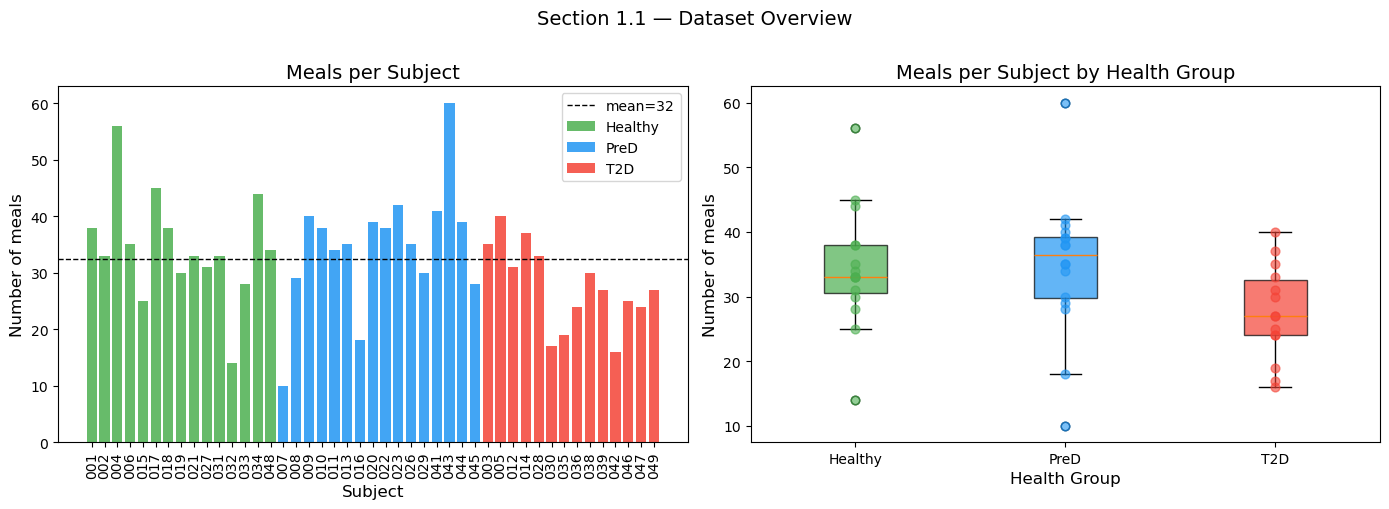

In [152]:
print("=" * 60)
print("1.1 — SUBJECTS & MEALS")
print("=" * 60)

print(f"Total subjects     : {meals_libre_df['subject'].nunique()}")
print(f"Total meals        : {len(meals_libre_df)}")
print(f"Avg meals/subject  : {len(meals_libre_df)/meals_libre_df['subject'].nunique():.1f}")

meals_per_sub = meals_libre_df.groupby('subject').size().reset_index(name='n_meals')
health_map    = bio_clean.set_index('subject')['Health_group']
meals_per_sub['Health_group'] = meals_per_sub['subject'].map(health_map)

print(f"\nMeals per subject (min/max/std):")
print(f"  min: {meals_per_sub['n_meals'].min()}  "
      f"max: {meals_per_sub['n_meals'].max()}  "
      f"std: {meals_per_sub['n_meals'].std():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left — bar chart: meals per subject, colored by health group
ax = axes[0]
for group in ['Healthy', 'PreD', 'T2D']:
    subset = meals_per_sub[meals_per_sub['Health_group'] == group]
    ax.bar(subset['subject'], subset['n_meals'],
           color=HEALTH_COLORS[group], label=group, alpha=0.85)

ax.axhline(meals_per_sub['n_meals'].mean(), color='black',
           linestyle='--', linewidth=1, label=f"mean={meals_per_sub['n_meals'].mean():.0f}")
ax.set_xlabel("Subject")
ax.set_ylabel("Number of meals")
ax.set_title("Meals per Subject")
ax.tick_params(axis='x', rotation=90)
ax.legend()

# Right — boxplot: meals per subject by health group
ax = axes[1]
groups = ['Healthy', 'PreD', 'T2D']
data_by_group = [meals_per_sub[meals_per_sub['Health_group'] == g]['n_meals']
                 for g in groups]
bp = ax.boxplot(data_by_group, patch_artist=True, labels=groups)
for patch, group in zip(bp['boxes'], groups):
    patch.set_facecolor(HEALTH_COLORS[group])
    patch.set_alpha(0.7)

# Overlay individual points
for i, (group, d) in enumerate(zip(groups, data_by_group), 1):
    ax.scatter([i] * len(d), d,
               color=HEALTH_COLORS[group], alpha=0.6, zorder=3, s=40)

ax.set_ylabel("Number of meals")
ax.set_title("Meals per Subject by Health Group")
ax.set_xlabel("Health Group")

plt.suptitle("Section 1.1 — Dataset Overview", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


1.2 — HEALTH GROUP DISTRIBUTION
              Subjects  Meals  Avg meals/subject
Health_group                                    
Healthy             15    517              34.50
PreD                16    556              34.80
T2D                 14    385              27.50


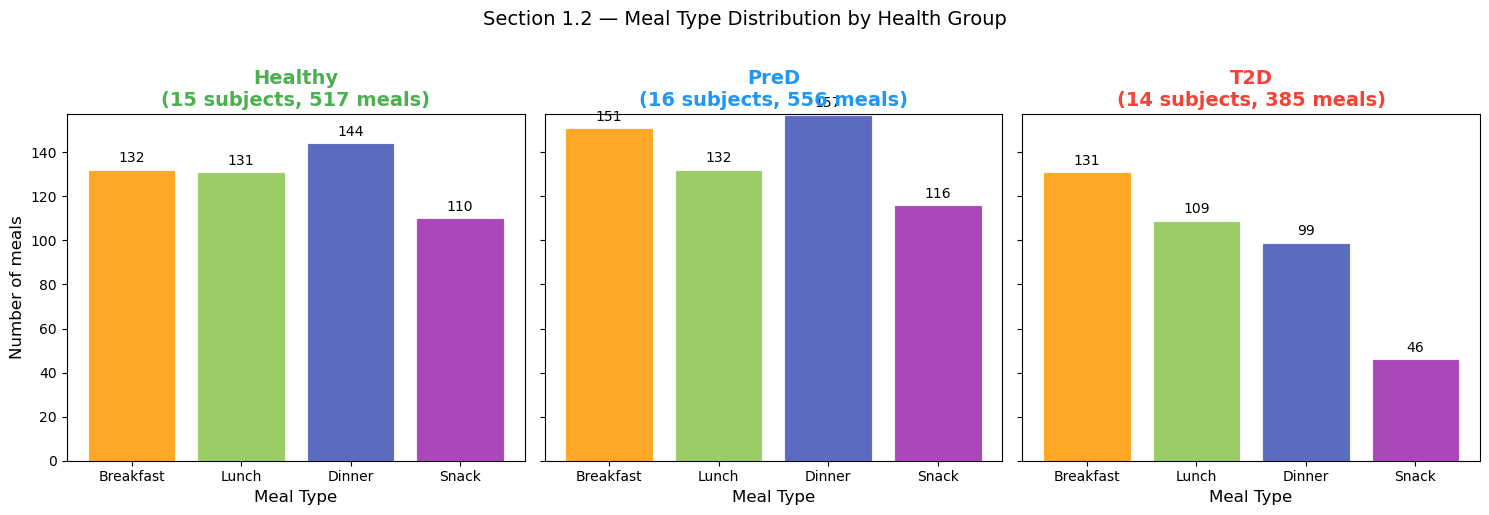

In [153]:
print("\n" + "=" * 60)
print("1.2 — HEALTH GROUP DISTRIBUTION")
print("=" * 60)
hg = bio_clean.groupby('Health_group').size().rename('Subjects')
hg_meals = meals_libre_df.groupby('Health_group').size().rename('Meals')
hg_summary = pd.concat([hg, hg_meals], axis=1)
hg_summary['Avg meals/subject'] = (hg_summary['Meals'] /
                                    hg_summary['Subjects']).round(1)
print(hg_summary.to_string())

meal_counts = (meals_libre_df
               .groupby(['Health_group', 'Meal_Type'])
               .size()
               .reset_index(name='n_meals'))

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

meal_types = ['Breakfast', 'Lunch', 'Dinner', 'Snack']
bar_colors  = ['#FF9800', '#8BC34A', '#3F51B5', '#9C27B0']

for ax, group in zip(axes, ['Healthy', 'PreD', 'T2D']):
    subset = (meal_counts[meal_counts['Health_group'] == group]
              .set_index('Meal_Type')['n_meals']  
              .reindex(meal_types, fill_value=0))  

    bars = ax.bar(subset.index, subset.values,
                  color=bar_colors, alpha=0.85, edgecolor='white', linewidth=0.8)

    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 2,
                str(int(h)), ha='center', va='bottom', fontsize=10)

    n_subs = hg.loc[group]
    ax.set_title(f"{group}\n({n_subs} subjects, {subset.sum()} meals)",
                 color=HEALTH_COLORS[group], fontweight='bold')
    ax.set_xlabel("Meal Type")
    ax.set_ylim(0, subset.values.max() * 1.2)

axes[0].set_ylabel("Number of meals")
plt.suptitle("Section 1.2 — Meal Type Distribution by Health Group",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [16]:
meals_libre_df

,subject,Meal_Type,Timestamp,Libre_trace,Baseline_Libre,iAUC_libre,AUC_libre,Dexcom_trace,Baseline_Dexcom,iAUC_dexcom,AUC_dexcom,dexcom_complete,Calories,Carbs_g,Protein_g,...,Health_group,Age,Gender,BMI,A1c,Fasting_glucose,Insulin,HOMA_IR,Triglycerides,Cholesterol,HDL,Non_HDL,LDL,VLDL,Cho_HDL_ratio
0,001,Lunch,2020-05-01 14:23:00,"[69.8, 68.06666666666666, 74.86666666666666, 8...",69.80,1496.31,9856.00,"[109.4, 113.8, 114.2, 112.4, 115.2, 116.8, 117...",109.40,2318.22,41580.00,True,1170.00,85.00,88.00,...,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
1,001,Dinner,2020-05-01 20:48:00,"[84.8, 96.2, 113.2, 110.6, 96.4, 94.2, 94.4, 9...",84.80,1617.00,11793.00,"[114.8, 114.2, 114.0, 118.0, 115.8, 132.6, 146...",114.80,4265.70,45577.50,True,80.00,18.00,0.00,...,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
2,001,Snack,2020-05-02 00:15:00,"[81.0, 86.0, 107.0, 113.0, 96.0, 90.0, 95.0, 8...",81.00,1650.00,11370.00,"[97.4, 99.8, 103.4, 105.4, 108.2, 114.6, 122.6...",97.40,5580.00,40644.00,True,110.00,24.00,0.00,...,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
3,001,Breakfast,2020-05-02 08:18:00,"[88.4, 98.0, 114.8, 114.0, 96.8, 93.8, 100.4, ...",88.40,1348.51,11848.50,"[101.8, 99.4, 95.8, 95.8, 101.6, 116.6, 127.2,...",101.80,3760.20,39508.50,True,448.00,66.00,22.00,...,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
4,001,Lunch,2020-05-02 12:00:00,"[82.0, 88.0, 103.0, 97.0, 76.0, 75.0, 92.0, 98...",82.00,1039.47,10747.50,"[80.0, 85.4, 92.2, 97.8, 102.4, 109.2, 115.0, ...",80.00,5656.05,31639.50,True,840.00,89.00,17.00,...,Healthy,27,M,22.27,5.40,91,2.50,0.56,67,216,74,142,130,13,2.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1453,049,Breakfast,2025-05-19 07:06:00,"[132.6, 162.46666666666667, 214.66666666666663...",132.60,13412.50,29324.50,"[164.8, 164.0, 167.0, 175.6, 186.6, 199.4, 214...",164.80,38481.10,97801.50,True,712.00,66.00,22.00,...,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40
1454,049,Lunch,2025-05-19 13:37:00,"[82.93333333333334, 90.46666666666668, 108.733...",82.93,5520.50,15472.50,"[94.8, 95.8, 96.8, 98.6, 102.2, 106.2, 112.6, ...",94.80,18828.00,52956.00,True,445.00,43.00,20.00,...,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40
1455,049,Dinner,2025-05-19 20:21:00,"[88.46666666666667, 108.06666666666666, 148.26...",88.47,8825.50,19441.50,"[106.0, 107.8, 112.0, 115.8, 124.8, 136.6, 157...",106.00,32439.00,70599.00,True,370.00,38.00,26.00,...,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40
1456,049,Breakfast,2025-05-20 07:06:00,"[138.33333333333334, 162.4, 199.8, 225.8, 221....",138.33,5922.50,22522.50,"[152.6, 149.8, 156.2, 168.8, 180.0, 190.0, 201...",152.60,18388.69,73294.50,True,268.00,24.00,22.00,...,T2D,58,F,36.09,7.20,148,25.20,9.21,124,146,43,103,81,25,3.40


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

def plot_cgm_day_comparison(subject_id, day_index=0):

    # Load data 
    path = os.path.join(DATA_PATH, f"CGMacros-{subject_id}", f"CGMacros-{subject_id}.csv")
    data = pd.read_csv(path, parse_dates=['Timestamp'])
    data = data.sort_values('Timestamp').reset_index(drop=True)

    data['Date'] = data['Timestamp'].dt.date
    unique_days  = sorted(data['Date'].unique())

    if day_index >= len(unique_days):
        day_index = 0
    chosen_day = unique_days[day_index]
    day_data   = data[data['Date'] == chosen_day].copy().reset_index(drop=True)
    print(f"Subject {subject_id} | Day: {chosen_day} | Rows: {len(day_data)}")

    # CGM traces 
    timestamps = day_data['Timestamp']
    libre_gl   = day_data['Libre GL'].values  if 'Libre GL'  in day_data.columns else None
    dexcom_gl  = day_data['Dexcom GL'].values if 'Dexcom GL' in day_data.columns else None

    # Meals 
    meal_rows = day_data[day_data['Meal Type'].notna()].copy()

    SENSOR_FLOOR    = 40
    FASTING_REF     = 100
    HYPER_THRESHOLD = 180

    # Build shading regions
    shade_regions = []

    for _, meal_row in meal_rows.iterrows():
        meal_time = meal_row['Timestamp']
        meal_type = str(meal_row['Meal Type']).strip()

        # Per-meal baseline = Libre reading at meal onset
        meal_idx = timestamps[timestamps == meal_time].index
        if len(meal_idx) > 0 and libre_gl is not None:
            meal_baseline = libre_gl[meal_idx[0]]
            if np.isnan(meal_baseline):
                meal_baseline = FASTING_REF
        else:
            meal_baseline = FASTING_REF

        print(f"  {meal_type} at {meal_time.strftime('%H:%M')} — baseline: {meal_baseline:.1f} mg/dL")

        # 2-hour post-meal window
        window_mask  = (timestamps >= meal_time) & \
                       (timestamps <= meal_time + pd.Timedelta(hours=2))
        window_times = timestamps[window_mask].values
        window_gl    = libre_gl[window_mask.values] if libre_gl is not None else []

        if len(window_gl) > 1:
            shade_regions.append((window_times, window_gl, meal_baseline, meal_type))

    # Plot 
    fig, ax = plt.subplots(figsize=(18, 5))

    # iAUC shading
    for i, (w_times, w_gl, meal_baseline, _) in enumerate(shade_regions):
        w_times_dt = pd.to_datetime(w_times)
        gl_above   = np.where(w_gl > meal_baseline, w_gl, meal_baseline)
        ax.fill_between(w_times_dt, meal_baseline, gl_above,
                        alpha=0.35, color='steelblue', zorder=1,
                        label='iAUC' if i == 0 else '')

    # Dexcom trace
    if dexcom_gl is not None:
        ax.plot(timestamps, dexcom_gl,
                color='#C0392B', linewidth=1.2, marker='o', markersize=2,
                label='Dexcom', zorder=3)

    # Libre trace
    if libre_gl is not None:
        ax.plot(timestamps, libre_gl,
                color='black', linewidth=1.5, marker='o', markersize=3,
                label='Freestyle Libre', zorder=4)

    # Clinical reference lines
    ax.axhline(SENSOR_FLOOR,    color='#E74C3C',   linestyle='--', linewidth=1.0, alpha=0.7)
    ax.axhline(FASTING_REF,     color='steelblue', linestyle='--', linewidth=1.0, alpha=0.5)
    ax.axhline(HYPER_THRESHOLD, color='#E74C3C',   linestyle='--', linewidth=1.0, alpha=0.7)

    # Reference labels
    day_start = pd.Timestamp(chosen_day)
    day_end   = day_start + pd.Timedelta(days=1)
    ax.text(day_start + pd.Timedelta(minutes=5), 42,  '40',  color='#E74C3C',   fontsize=8, va='bottom')
    ax.text(day_start + pd.Timedelta(minutes=5), 102, '100', color='steelblue', fontsize=8, va='bottom')
    ax.text(day_start + pd.Timedelta(minutes=5), 182, '180', color='#E74C3C',   fontsize=8, va='bottom')

    # Meal markers
    for i, (_, meal_row) in enumerate(meal_rows.iterrows(), start=1):
        meal_time = meal_row['Timestamp']
        meal_type = str(meal_row['Meal Type']).strip()

        ax.axvline(meal_time, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)

        meal_mask = timestamps == meal_time
        y_pos = libre_gl[meal_mask.values][0] if (meal_mask.any() and libre_gl is not None) else 150
        if np.isnan(y_pos):
            y_pos = 150

        # Diamond + number
        ax.plot(meal_time, y_pos, marker='D', color='#E74C3C', markersize=10, zorder=5)
        ax.text(meal_time, y_pos + 8, str(i),
                ha='center', va='bottom', fontsize=8, fontweight='bold', color='white',
                bbox=dict(boxstyle='round,pad=0.1', facecolor='#E74C3C', edgecolor='none'))

        # Meal type label at top
        ax.text(meal_time, 270, meal_type,
                ha='center', va='top', fontsize=8,
                color='#E74C3C', fontweight='bold')

    # Formatting 
    ax.set_xlim(day_start, day_end)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%I:%M %p'))
    ax.xaxis.set_major_locator(plt.matplotlib.dates.HourLocator(interval=2))
    plt.xticks(rotation=0, fontsize=9)

    ax.set_ylim(0, 280)
    ax.set_ylabel('Glucose (mg/dL)', fontsize=11)
    ax.set_xlabel('Time', fontsize=11)

    subj_bio = bio_clean[bio_clean['subject'] == subject_id]
    hgroup   = subj_bio['Health_group'].values[0] if len(subj_bio) > 0 else '?'
    ax.set_title(f'Subject {subject_id} ({hgroup}) — {chosen_day}', fontsize=12)

    ax.legend(loc='upper right', fontsize=10, framealpha=0.9)
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'cgm_day_subject{subject_id}_day{day_index}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: cgm_day_subject{subject_id}_day{day_index}.png")

Subject 001 | Day: 2020-05-06 | Rows: 1440
  Breakfast at 08:54 — baseline: 94.2 mg/dL
  Lunch at 12:25 — baseline: 84.7 mg/dL
  Dinner at 19:56 — baseline: 80.1 mg/dL
  Dinner at 20:58 — baseline: 87.2 mg/dL


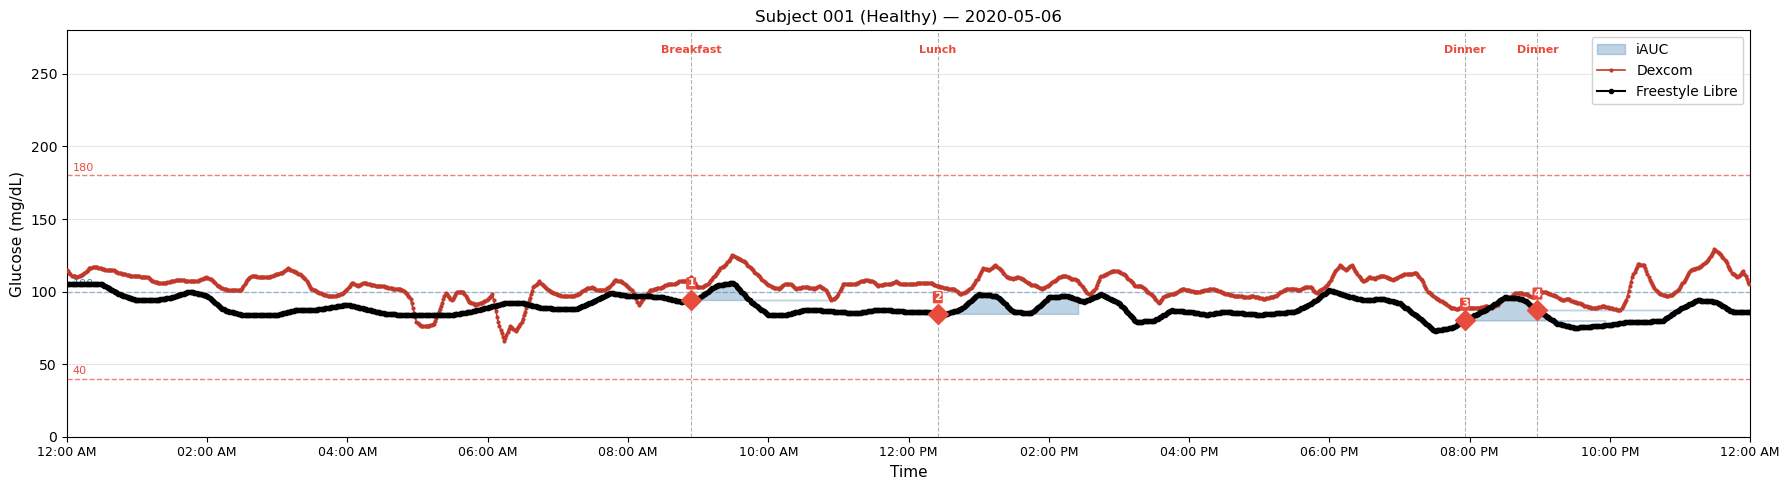

Saved: cgm_day_subject001_day5.png
Subject 029 | Day: 2024-01-18 | Rows: 1440
  breakfast at 05:44 — baseline: 115.7 mg/dL
  lunch at 11:56 — baseline: 111.7 mg/dL
  dinner at 17:04 — baseline: 92.6 mg/dL


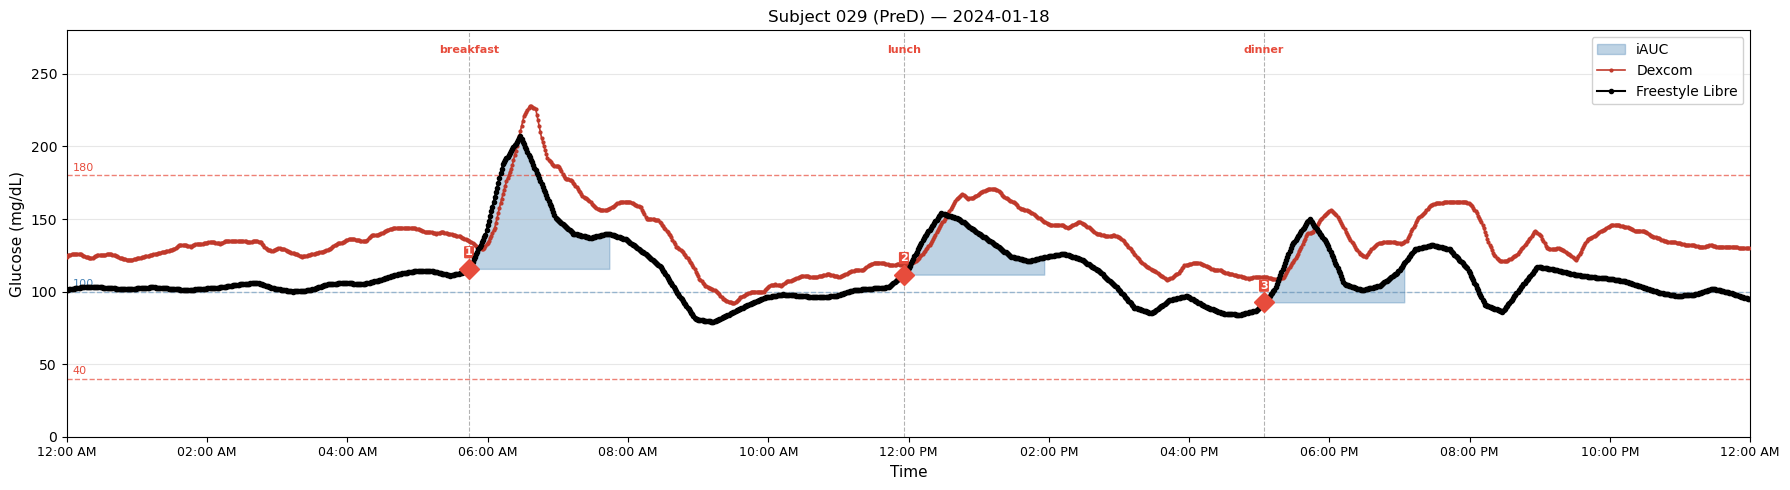

Saved: cgm_day_subject029_day1.png
Subject 003 | Day: 2020-03-14 | Rows: 1440
  Breakfast at 09:35 — baseline: 122.9 mg/dL
  Lunch at 13:33 — baseline: 76.0 mg/dL
  Dinner at 19:57 — baseline: 91.2 mg/dL


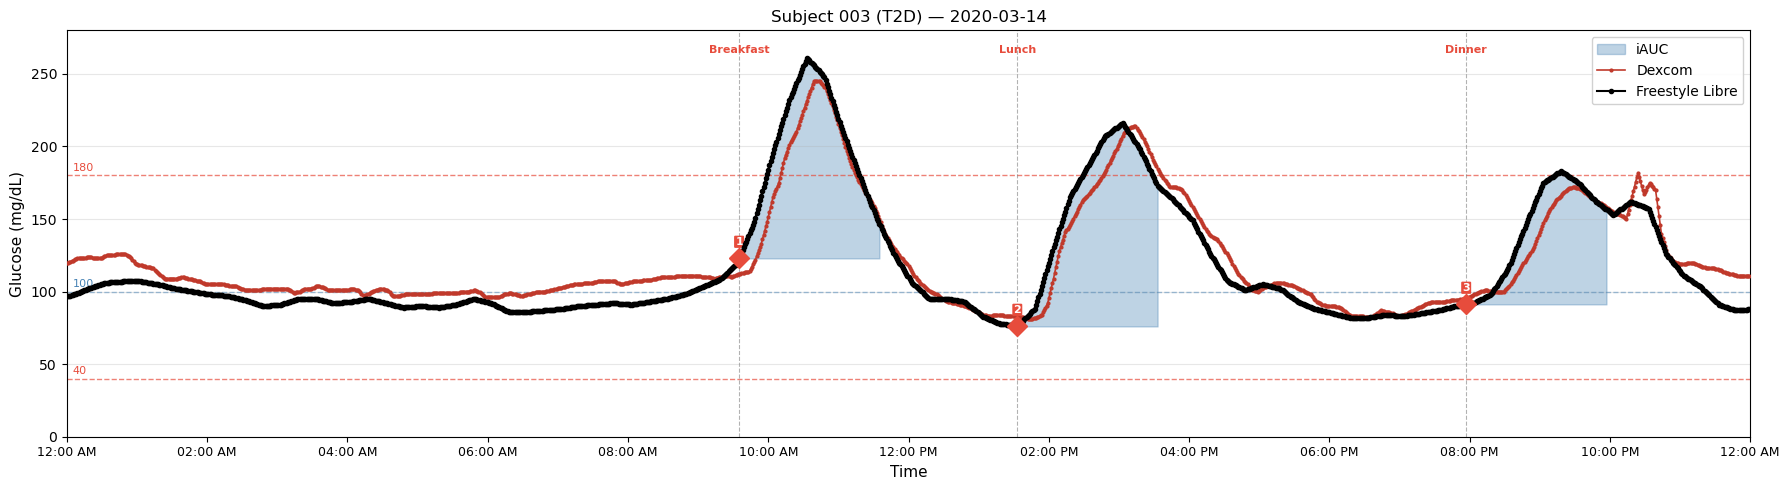

Saved: cgm_day_subject003_day3.png


In [154]:
plot_cgm_day_comparison('001', day_index=5) # Healthy subject
plot_cgm_day_comparison('029', day_index=1) # Prediabetic subject
plot_cgm_day_comparison('003', day_index=3) # Type2 diabetes subject

1.3 — DEMOGRAPHICS OVERVIEW
               Age                 BMI                   A1c                Fasting_glucose                 HOMA_IR                
              mean   std min max  mean  std   min   max mean  std  min  max            mean   std  min  max    mean  std  min   max
Health_group                                                                                                                       
Healthy      38.73 14.53  18  64 28.15 6.41 21.13 42.38 5.23 0.32 4.60 5.60           95.67  9.46   79  116    2.34 1.48 0.56  5.03
PreD         51.56 10.65  34  69 33.43 7.45 20.69 49.09 5.98 0.22 5.70 6.40          116.25 15.59   96  148    5.23 3.58 0.85 16.96
T2D          54.21  5.63  45  62 31.76 5.26 24.99 43.27 7.24 0.57 6.50 8.50          152.57 29.58  101  218    5.58 2.55 1.32 10.96

Gender distribution:
Gender         F  M
Health_group       
Healthy       10  5
PreD          11  5
T2D            8  6


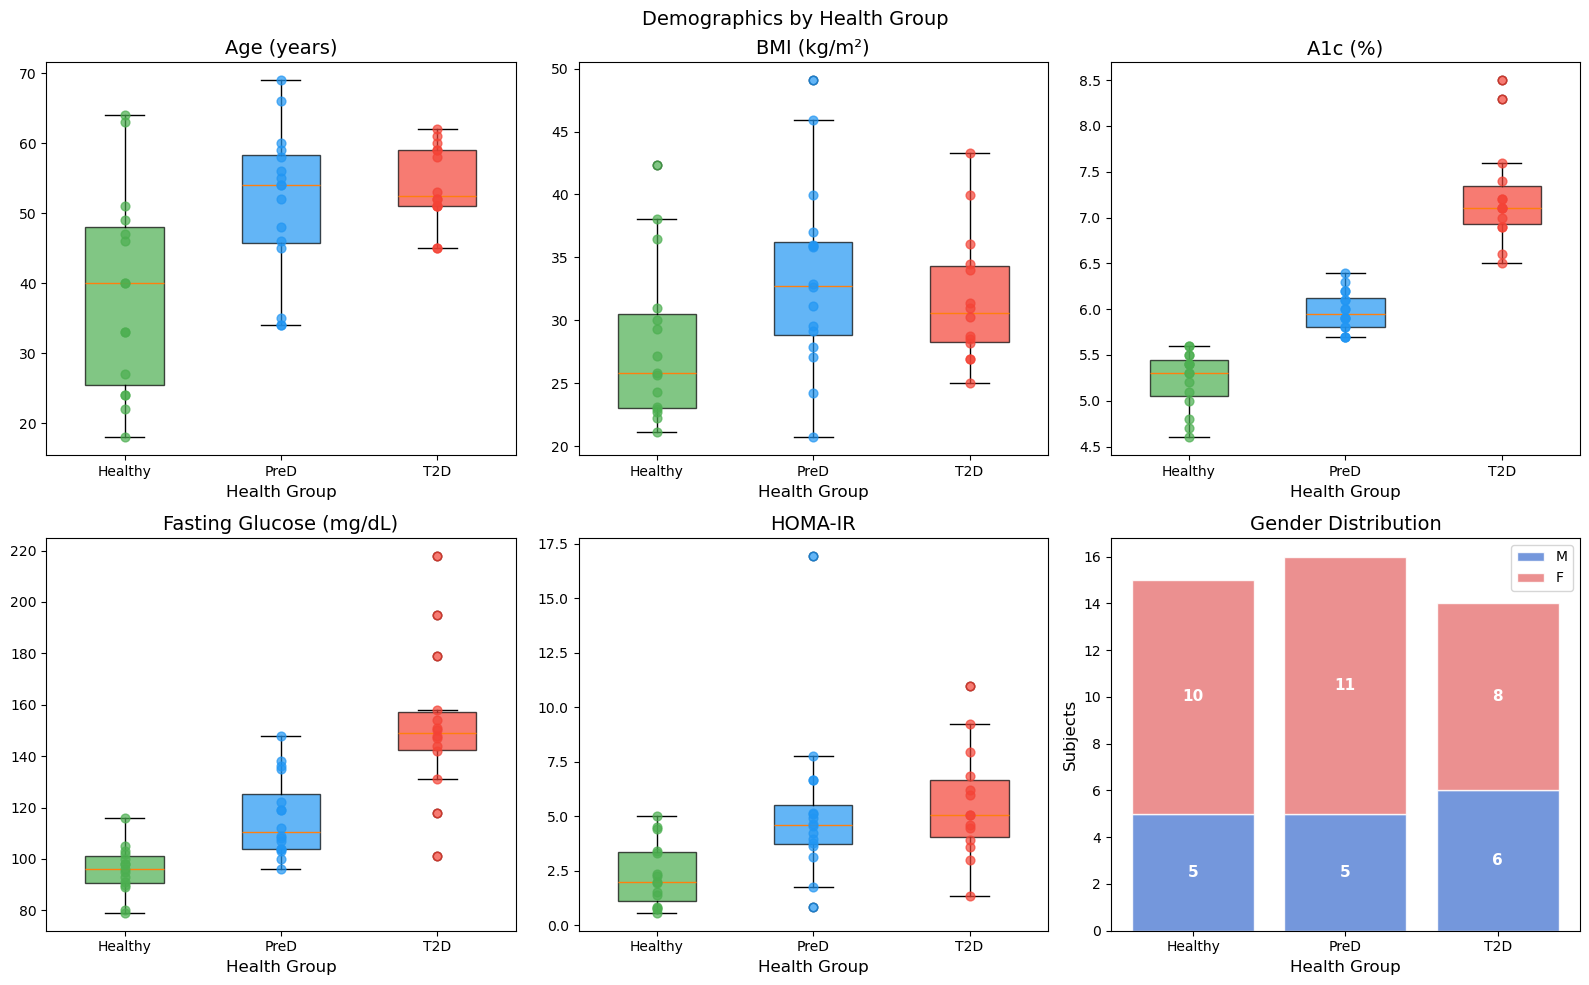

In [156]:
print("=" * 60)
print("1.3 — DEMOGRAPHICS OVERVIEW")
print("=" * 60)

# Numerical summary per health group 
demo_cols = ['Age', 'BMI', 'A1c', 'Fasting_glucose', 'HOMA_IR']
bio_stats = (bio_clean
             .groupby('Health_group')[demo_cols]
             .agg(['mean', 'std', 'min', 'max'])
             .round(2))
print(bio_stats.to_string())

print("\nGender distribution:")
print(bio_clean.groupby(['Health_group', 'Gender'])
               .size().unstack(fill_value=0).to_string())

# Plots 
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

groups  = ['Healthy', 'PreD', 'T2D']
colors  = [HEALTH_COLORS[g] for g in groups]

# One panel per demographic feature
demo_plot_cols = {
    'Age':             'Age (years)',
    'BMI':             'BMI (kg/m²)',
    'A1c':             'A1c (%)',
    'Fasting_glucose': 'Fasting Glucose (mg/dL)',
    'HOMA_IR':         'HOMA-IR',
}

for ax, (col, label) in zip(axes, demo_plot_cols.items()):
    data_by_group = [bio_clean[bio_clean['Health_group'] == g][col] for g in groups]

    bp = ax.boxplot(data_by_group, patch_artist=True,
                    tick_labels=groups, widths=0.5)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    # Overlay individual subject points
    for i, (g, d) in enumerate(zip(groups, data_by_group), 1):
        ax.scatter([i] * len(d), d,
                   color=HEALTH_COLORS[g], alpha=0.7, zorder=3, s=40)

    ax.set_title(label)
    ax.set_xlabel("Health Group")

# Last panel - Gender stacked bar
ax = axes[5]
gender_counts = (bio_clean.groupby(['Health_group', 'Gender'])
                           .size().unstack(fill_value=0))
gender_counts = gender_counts.reindex(groups)
bottom = np.zeros(3)
for gender, color in zip(['M', 'F'], ['#5C85D6', '#E87D7D']):
    if gender in gender_counts.columns:
        vals = gender_counts[gender].values
        ax.bar(groups, vals, bottom=bottom,
               color=color, alpha=0.85, label=gender, edgecolor='white')
        # Count labels
        for j, (v, b) in enumerate(zip(vals, bottom)):
            if v > 0:
                ax.text(j, b + v/2, str(v),
                        ha='center', va='center',
                        fontsize=11, fontweight='bold', color='white')
        bottom += vals

ax.set_title("Gender Distribution")
ax.set_xlabel("Health Group")
ax.set_ylabel("Subjects")
ax.legend()

plt.suptitle("Demographics by Health Group", fontsize=14)
plt.tight_layout()
plt.show()

### Kruskal Wallis Test

For cohort studies, it basically confirms the 3 groups are genuinely different populations, not just random splits. For feature selection modelling - this tells us which features differ between health groups, not which features predict iAUC.

In [157]:
from scipy.stats import kruskal

print("\nKruskal-Wallis tests (group differences):")
for col in ['Age', 'BMI', 'A1c', 'Fasting_glucose', 'HOMA_IR']:
    groups_data = [bio_clean[bio_clean['Health_group'] == g][col] 
                   for g in ['Healthy', 'PreD', 'T2D']]
    stat, p = kruskal(*groups_data)
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    print(f"  {col:20s}: p={p:.4f}  {sig}")


Kruskal-Wallis tests (group differences):
  Age                 : p=0.0057  **
  BMI                 : p=0.0691  ns
  A1c                 : p=0.0000  ***
  Fasting_glucose     : p=0.0000  ***
  HOMA_IR             : p=0.0005  ***


### Section 2 - Target Variable Analysis (iAUC vs AUC)
Goal: Deeply understand what we are trying to predict

2.1 — DESCRIPTIVE STATISTICS

── Overall (meals_libre_df) ────────────────────────────
       iAUC_libre  AUC_libre
count     1458.00    1458.00
mean      2880.80   14617.30
std       2749.10    4807.40
min          0.00    5908.50
25%        879.40   11315.40
50%       2095.00   13392.00
75%       3919.90   16844.90
max      15460.50   40980.00

── Overall (meals_dexcom_df) ───────────────────────────
       iAUC_dexcom  AUC_dexcom
count      1425.00     1425.00
mean      10094.60    53386.80
std        9351.20    14898.00
min           0.00    18660.00
25%        3378.20    43050.00
50%        7470.00    50122.50
75%       14265.20    60127.50
max       62295.00   135154.50

── iAUC_libre by Health Group ──────────────────────────
                mean     std  median  min      max
Health_group                                      
Healthy      1818.90 2017.90 1250.00 0.00 14664.50
PreD         2871.40 2339.10 2304.40 1.00 13173.00
T2D          4320.10 3420.80 3456.50 0.40 15460.50

─

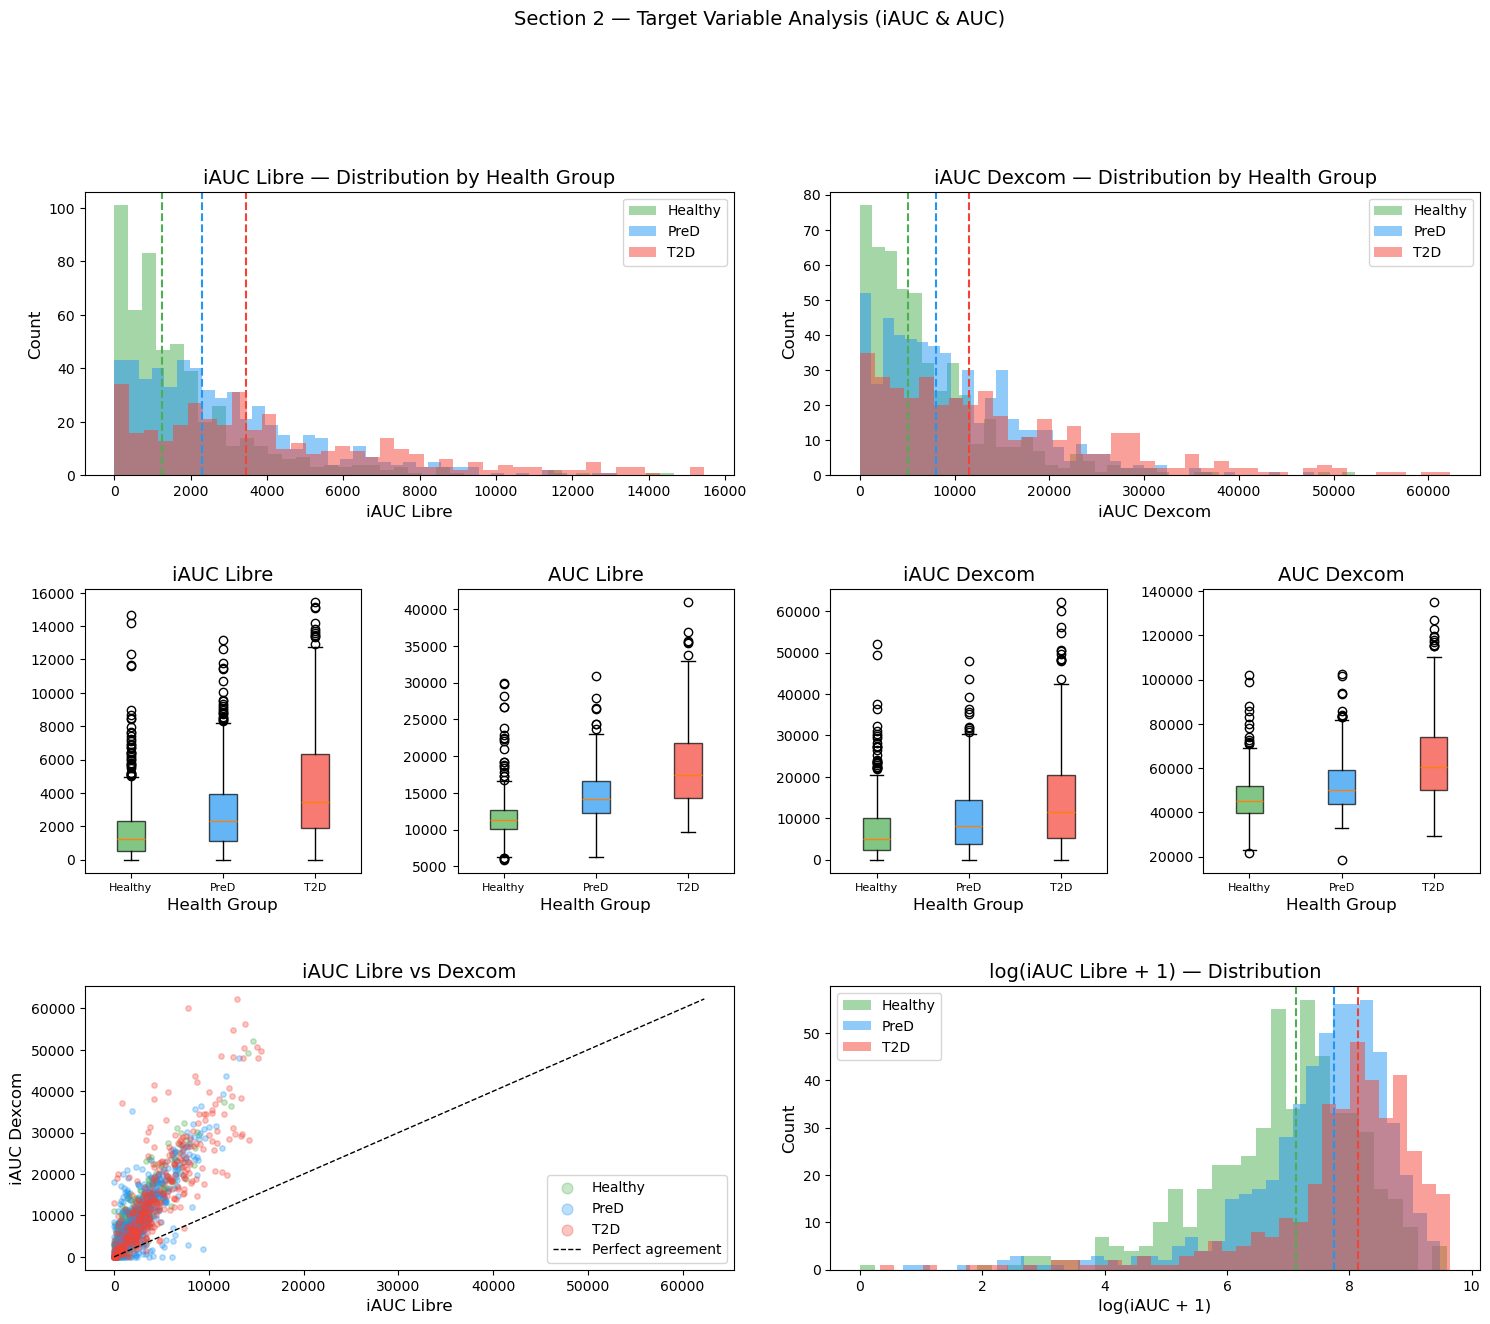

In [158]:
print("=" * 60)
print("2.1 — DESCRIPTIVE STATISTICS")
print("=" * 60)

target_cols = ['iAUC_libre', 'AUC_libre', 'iAUC_dexcom', 'AUC_dexcom']

# Overall stats
print("\n── Overall (meals_libre_df) ────────────────────────────")
print(meals_libre_df[['iAUC_libre', 'AUC_libre']].describe().round(1).to_string())

print("\n── Overall (meals_dexcom_df) ───────────────────────────")
print(meals_dexcom_df[['iAUC_dexcom', 'AUC_dexcom']].describe().round(1).to_string())

# By health group
print("\n── iAUC_libre by Health Group ──────────────────────────")
print(meals_libre_df.groupby('Health_group')['iAUC_libre']
      .agg(['mean','std','median','min','max']).round(1).to_string())

print("\n── iAUC_dexcom by Health Group ─────────────────────────")
print(meals_dexcom_df.groupby('Health_group')['iAUC_dexcom']
      .agg(['mean','std','median','min','max']).round(1).to_string())

# Statistical significance between groups
from scipy.stats import kruskal, mannwhitneyu

print("\n── Kruskal-Wallis across health groups ─────────────────")
for col, df in [('iAUC_libre', meals_libre_df), 
                ('AUC_libre',  meals_libre_df),
                ('iAUC_dexcom', meals_dexcom_df), 
                ('AUC_dexcom',  meals_dexcom_df)]:
    groups_data = [df[df['Health_group'] == g][col].dropna()
                   for g in ['Healthy', 'PreD', 'T2D']]
    stat, p = kruskal(*groups_data)
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    print(f"  {col:20s}: p={p:.4f}  {sig}")

# Plots 
fig = plt.figure(figsize=(18, 14))
gs  = gridspec.GridSpec(3, 4, figure=fig, hspace=0.4, wspace=0.35)

groups = ['Healthy', 'PreD', 'T2D']
colors = [HEALTH_COLORS[g] for g in groups]

# Row 1: iAUC distributions 
# Libre histogram
ax = fig.add_subplot(gs[0, :2])
for g in groups:
    vals = meals_libre_df[meals_libre_df['Health_group'] == g]['iAUC_libre']
    ax.hist(vals, bins=40, alpha=0.5, color=HEALTH_COLORS[g], label=g)
    ax.axvline(vals.median(), color=HEALTH_COLORS[g],
               linestyle='--', linewidth=1.5)
ax.set_title("iAUC Libre — Distribution by Health Group")
ax.set_xlabel("iAUC Libre")
ax.set_ylabel("Count")
ax.legend()

# Dexcom histogram
ax = fig.add_subplot(gs[0, 2:])
for g in groups:
    vals = meals_dexcom_df[meals_dexcom_df['Health_group'] == g]['iAUC_dexcom']
    ax.hist(vals, bins=40, alpha=0.5, color=HEALTH_COLORS[g], label=g)
    ax.axvline(vals.median(), color=HEALTH_COLORS[g],
               linestyle='--', linewidth=1.5)
ax.set_title("iAUC Dexcom — Distribution by Health Group")
ax.set_xlabel("iAUC Dexcom")
ax.set_ylabel("Count")
ax.legend()

# Row 2: Boxplots iAUC and AUC 
for col_idx, (col, df, title) in enumerate([
    ('iAUC_libre',  meals_libre_df,  'iAUC Libre'),
    ('AUC_libre',   meals_libre_df,  'AUC Libre'),
    ('iAUC_dexcom', meals_dexcom_df, 'iAUC Dexcom'),
    ('AUC_dexcom',  meals_dexcom_df, 'AUC Dexcom'),
]):
    ax = fig.add_subplot(gs[1, col_idx])
    data_by_group = [df[df['Health_group'] == g][col].dropna() for g in groups]
    bp = ax.boxplot(data_by_group, patch_artist=True, tick_labels=groups)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    ax.set_title(title)
    ax.set_xlabel("Health Group")
    ax.tick_params(axis='x', labelsize=8)

# Row 3: iAUC Libre vs iAUC Dexcom scatter + log-transformed iAUC 
# Scatter: Libre vs Dexcom iAUC
ax = fig.add_subplot(gs[2, :2])
for g in groups:
    subset = meals_dexcom_df[meals_dexcom_df['Health_group'] == g]
    ax.scatter(subset['iAUC_libre'], subset['iAUC_dexcom'],
               color=HEALTH_COLORS[g], alpha=0.3, s=15, label=g)

# Perfect agreement line
max_val = meals_dexcom_df[['iAUC_libre','iAUC_dexcom']].max().max()
ax.plot([0, max_val], [0, max_val], 'k--', linewidth=1, label='Perfect agreement')
ax.set_xlabel("iAUC Libre")
ax.set_ylabel("iAUC Dexcom")
ax.set_title("iAUC Libre vs Dexcom")
ax.legend(markerscale=2)

# Log-transformed iAUC distribution
ax = fig.add_subplot(gs[2, 2:])
for g in groups:
    vals = meals_libre_df[meals_libre_df['Health_group'] == g]['iAUC_libre']
    log_vals = np.log1p(vals)
    ax.hist(log_vals, bins=40, alpha=0.5, color=HEALTH_COLORS[g], label=g)
    ax.axvline(log_vals.median(), color=HEALTH_COLORS[g],
               linestyle='--', linewidth=1.5)
ax.set_title("log(iAUC Libre + 1) — Distribution")
ax.set_xlabel("log(iAUC + 1)")
ax.set_ylabel("Count")
ax.legend()

plt.suptitle("Section 2 — Target Variable Analysis (iAUC & AUC)",
             fontsize=14, y=1.01)
plt.show()

iAUC_libre — median by Health Group × Meal Type:
Meal_Type     Breakfast  Dinner   Lunch   Snack
Health_group                                   
Healthy         1412.00 1199.00 1521.00  805.00
PreD            2518.00 2140.00 2552.00 1938.00
T2D             5811.00 2897.00 2737.00 1703.00


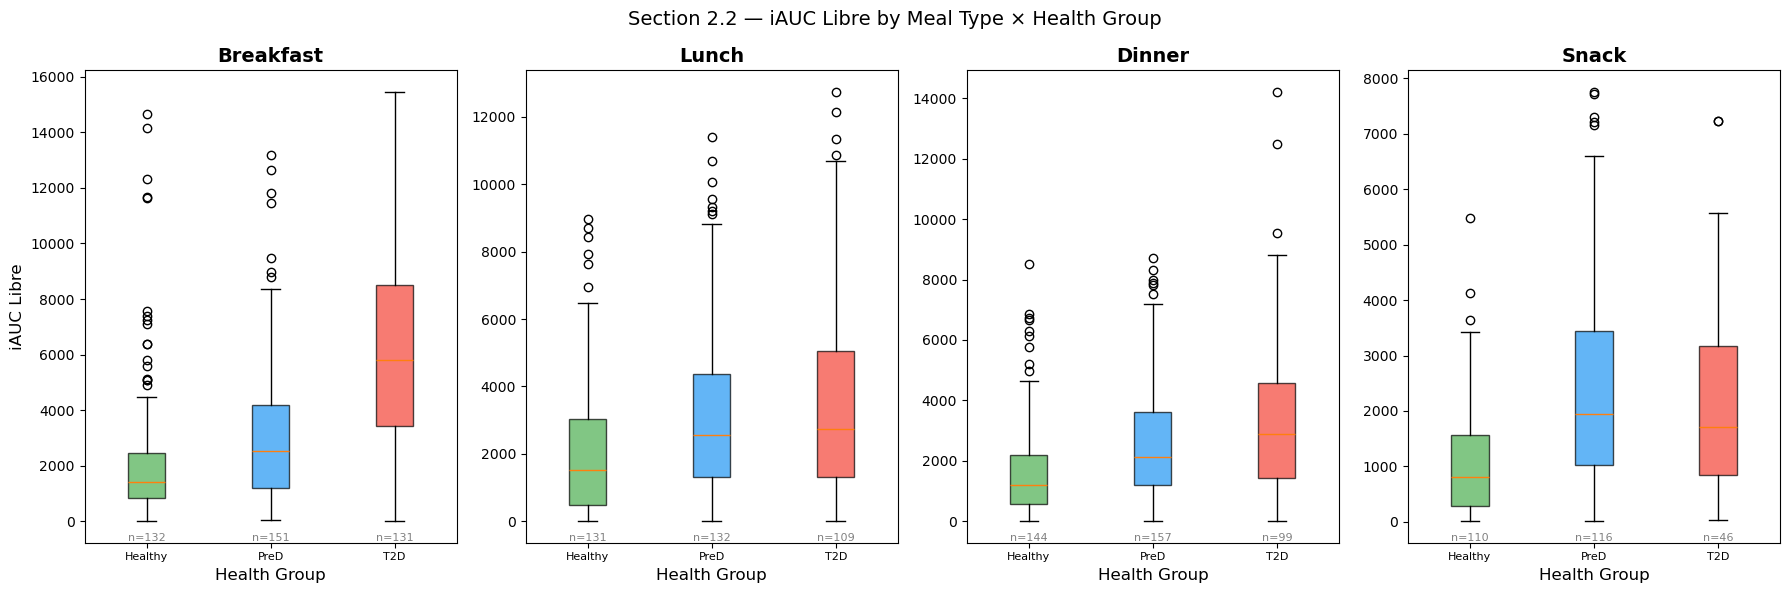


Kruskal-Wallis per meal type (health group effect on iAUC_libre):
  Breakfast   : p=0.0000  ***
  Lunch       : p=0.0001  ***
  Dinner      : p=0.0000  ***
  Snack       : p=0.0000  ***


In [159]:
# iAUC by Health Group × Meal Type 
print("iAUC_libre — median by Health Group × Meal Type:")
pivot = (meals_libre_df
         .groupby(['Health_group', 'Meal_Type'])['iAUC_libre']
         .median()
         .unstack()
         .round(0))
print(pivot.to_string())

# Plot: 2×2 grid - one panel per meal type 
meal_types = ['Breakfast', 'Lunch', 'Dinner', 'Snack']
fig, axes  = plt.subplots(1, 4, figsize=(18, 6), sharey=False)

for ax, meal in zip(axes, meal_types):
    subset = meals_libre_df[meals_libre_df['Meal_Type'] == meal]
    data_by_group = [subset[subset['Health_group'] == g]['iAUC_libre']
                     for g in ['Healthy', 'PreD', 'T2D']]

    bp = ax.boxplot(data_by_group, patch_artist=True,
                    tick_labels=['Healthy', 'PreD', 'T2D'])
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    # Median + n label
    for i, (g, d) in enumerate(zip(['Healthy','PreD','T2D'], data_by_group), 1):
        ax.text(i, ax.get_ylim()[0],
                f"n={len(d)}", ha='center', va='bottom',
                fontsize=8, color='gray')

    ax.set_title(f"{meal}", fontweight='bold')
    ax.set_xlabel("Health Group")
    ax.set_ylabel("iAUC Libre" if meal == 'Breakfast' else "")
    ax.tick_params(axis='x', labelsize=8)

plt.suptitle("Section 2.2 — iAUC Libre by Meal Type × Health Group",
             fontsize=14)
plt.tight_layout()
plt.show()

# tatistical tests: Kruskal-Wallis per meal type 
print("\nKruskal-Wallis per meal type (health group effect on iAUC_libre):")
for meal in meal_types:
    subset = meals_libre_df[meals_libre_df['Meal_Type'] == meal]
    groups_data = [subset[subset['Health_group'] == g]['iAUC_libre']
                   for g in ['Healthy', 'PreD', 'T2D']]
    stat, p = kruskal(*groups_data)
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
    print(f"  {meal:12s}: p={p:.4f}  {sig}")

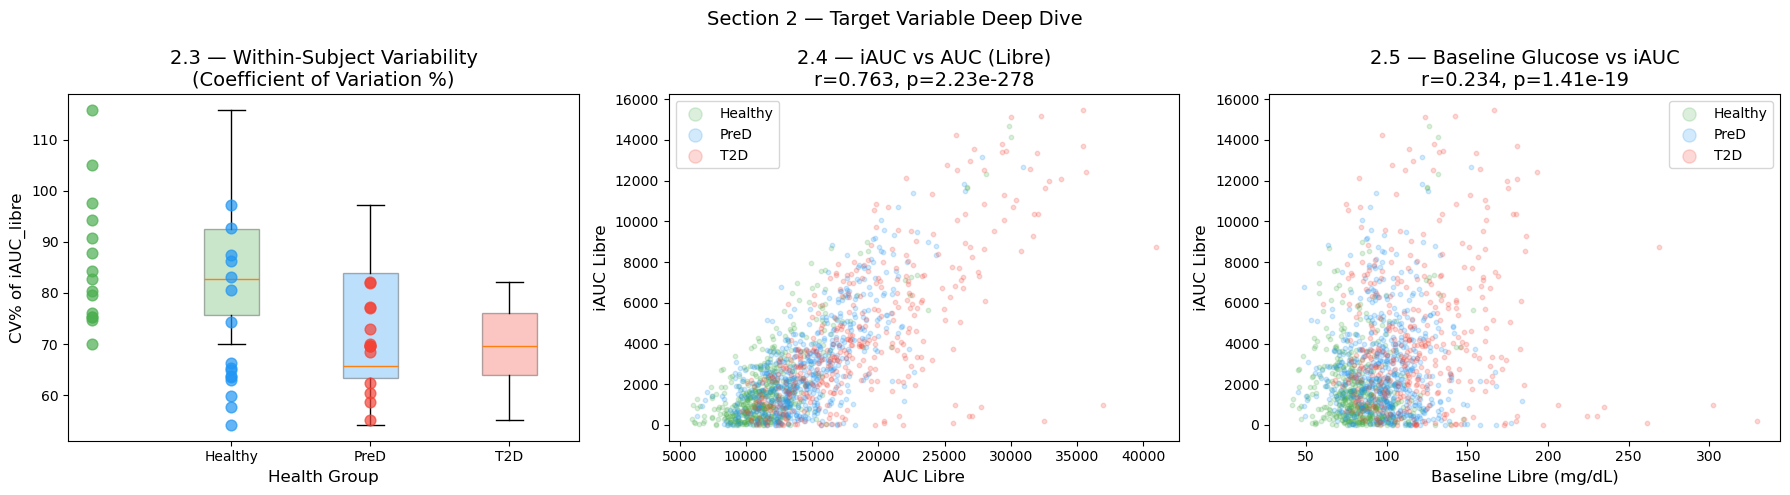

Within-subject CV% by health group:
              mean  median   min    max
Health_group                           
Healthy      86.00   82.70 69.90 115.80
PreD         72.50   65.80 54.20  97.30
T2D          69.70   69.60 55.10  82.20


In [161]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 2.3 Within-subject variability 
ax = axes[0]
subject_cv = (meals_libre_df
              .groupby('subject')['iAUC_libre']
              .agg(lambda x: x.std() / x.mean() * 100)  # coefficient of variation %
              .reset_index(name='CV_pct'))
subject_cv['Health_group'] = subject_cv['subject'].map(
    bio_clean.set_index('subject')['Health_group'])

for g in ['Healthy', 'PreD', 'T2D']:
    subset = subject_cv[subject_cv['Health_group'] == g]
    ax.scatter([g] * len(subset), subset['CV_pct'],
               color=HEALTH_COLORS[g], alpha=0.7, s=60, zorder=3)

bp = ax.boxplot(
    [subject_cv[subject_cv['Health_group'] == g]['CV_pct']
     for g in ['Healthy', 'PreD', 'T2D']],
    patch_artist=True, tick_labels=['Healthy', 'PreD', 'T2D'], widths=0.4)
for patch, g in zip(bp['boxes'], ['Healthy', 'PreD', 'T2D']):
    patch.set_facecolor(HEALTH_COLORS[g])
    patch.set_alpha(0.3)

ax.set_title("2.3 — Within-Subject Variability\n(Coefficient of Variation %)")
ax.set_ylabel("CV% of iAUC_libre")
ax.set_xlabel("Health Group")

# 2.4 iAUC vs AUC correlation 
ax = axes[1]
for g in ['Healthy', 'PreD', 'T2D']:
    subset = meals_libre_df[meals_libre_df['Health_group'] == g]
    ax.scatter(subset['AUC_libre'], subset['iAUC_libre'],
               color=HEALTH_COLORS[g], alpha=0.2, s=10, label=g)

r, p = pearsonr(meals_libre_df['AUC_libre'], meals_libre_df['iAUC_libre'])
ax.set_title(f"2.4 — iAUC vs AUC (Libre)\nr={r:.3f}, p={p:.2e}")
ax.set_xlabel("AUC Libre")
ax.set_ylabel("iAUC Libre")
ax.legend(markerscale=3)

# 2.5 Baseline glucose vs iAUC 
ax = axes[2]
for g in ['Healthy', 'PreD', 'T2D']:
    subset = meals_libre_df[meals_libre_df['Health_group'] == g]
    ax.scatter(subset['Baseline_Libre'], subset['iAUC_libre'],
               color=HEALTH_COLORS[g], alpha=0.2, s=10, label=g)

r, p = pearsonr(meals_libre_df['Baseline_Libre'], meals_libre_df['iAUC_libre'])
ax.set_title(f"2.5 — Baseline Glucose vs iAUC\nr={r:.3f}, p={p:.2e}")
ax.set_xlabel("Baseline Libre (mg/dL)")
ax.set_ylabel("iAUC Libre")
ax.legend(markerscale=3)

plt.suptitle("Section 2 — Target Variable Deep Dive", fontsize=14)
plt.tight_layout()
plt.show()

# Print CV stats 
print("Within-subject CV% by health group:")
print(subject_cv.groupby('Health_group')['CV_pct']
      .agg(['mean','median','min','max']).round(1).to_string())

Within-subject CV% by Health Group × Meal Type:
                        mean  median   min    max
Health_group Meal_Type                           
Healthy      Breakfast 60.40   56.70 36.70  88.60
             Dinner    79.50   72.80 41.40 166.50
             Lunch     86.80   86.30 62.80 106.00
             Snack     89.60   84.70 72.80 134.50
PreD         Breakfast 59.00   61.60 21.70  87.90
             Dinner    66.20   58.70 26.10 119.80
             Lunch     74.40   73.00  6.50 136.30
             Snack     67.30   71.40 20.20 104.00
T2D          Breakfast 42.50   42.30 27.40  66.80
             Dinner    68.70   62.70 31.20 117.90
             Lunch     77.50   77.60 24.80 118.10
             Snack     79.80   84.50 39.40 134.20


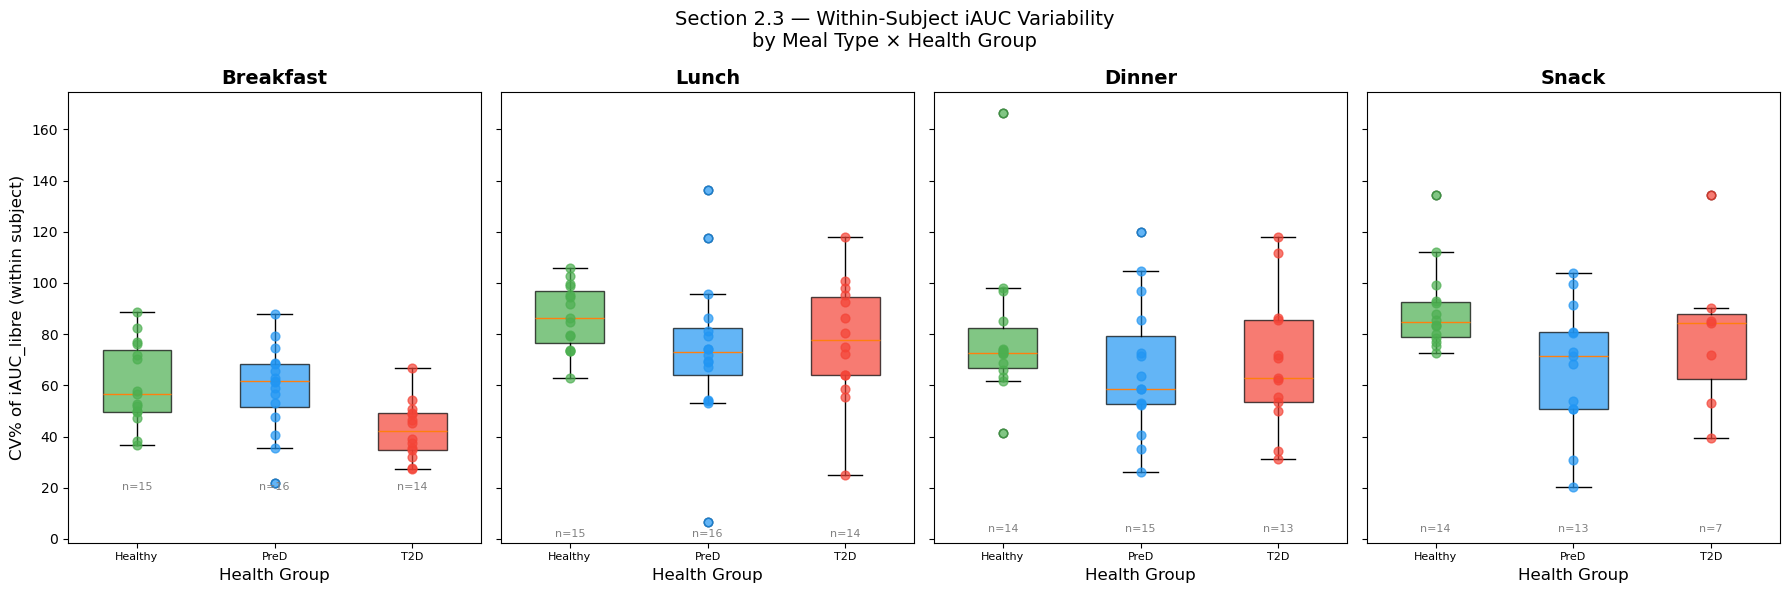

In [165]:
# CV per subject × meal type -> then aggregate by health group × meal type
subject_meal_cv = (meals_libre_df
                   .groupby(['subject', 'Meal_Type'])['iAUC_libre']
                   .agg(lambda x: x.std() / x.mean() * 100 if len(x) > 1 else np.nan)
                   .reset_index(name='CV_pct'))

subject_meal_cv['Health_group'] = subject_meal_cv['subject'].map(
    bio_clean.set_index('subject')['Health_group'])

# Drop subjects with only 1 meal in a category (CV undefined)
subject_meal_cv = subject_meal_cv.dropna(subset=['CV_pct'])

# summary 
print("Within-subject CV% by Health Group × Meal Type:")
pivot_cv = (subject_meal_cv
            .groupby(['Health_group', 'Meal_Type'])['CV_pct']
            .agg(['mean', 'median', 'min', 'max'])
            .round(1))
print(pivot_cv.to_string())

# Plot 
meal_types = ['Breakfast', 'Lunch', 'Dinner', 'Snack']
fig, axes  = plt.subplots(1, 4, figsize=(18, 6), sharey=True)

for ax, meal in zip(axes, meal_types):
    subset = subject_meal_cv[subject_meal_cv['Meal_Type'] == meal]
    data_by_group = [subset[subset['Health_group'] == g]['CV_pct']
                     for g in ['Healthy', 'PreD', 'T2D']]

    bp = ax.boxplot(data_by_group, patch_artist=True,
                    tick_labels=['Healthy', 'PreD', 'T2D'], widths=0.5)
    for patch, g in zip(bp['boxes'], ['Healthy', 'PreD', 'T2D']):
        patch.set_facecolor(HEALTH_COLORS[g])
        patch.set_alpha(0.7)

    # Individual subject points
    for i, (g, d) in enumerate(zip(['Healthy', 'PreD', 'T2D'], data_by_group), 1):
        ax.scatter([i] * len(d), d,
                   color=HEALTH_COLORS[g], alpha=0.7, s=40, zorder=3)

    # n labels
    for i, d in enumerate(data_by_group, 1):
        ax.text(i, ax.get_ylim()[0] if ax.get_ylim()[0] > 0 else 2,
                f"n={len(d)}", ha='center', va='bottom',
                fontsize=8, color='gray')

    ax.set_title(f"{meal}", fontweight='bold')
    ax.set_xlabel("Health Group")
    ax.tick_params(axis='x', labelsize=8)

axes[0].set_ylabel("CV% of iAUC_libre (within subject)")
plt.suptitle("Section 2.3 — Within-Subject iAUC Variability\nby Meal Type × Health Group",
             fontsize=14)
plt.tight_layout()
plt.show()

### Breakfast has the lowest CV% across ALL health groups

```
                Breakfast   Lunch    Dinner   Snack
Healthy CV%:    60.4        86.8     79.5     89.6
PreD CV%:       59.0        74.4     66.2     67.3
T2D CV%:        42.5        77.5     68.7     79.8
```

**Breakfast is 20-40% more consistent than other meal types** — meaning glucose response to breakfast is more predictable from meal to meal than response to lunch, dinner or snacks.

---

### Why this makes biological sense

**Breakfast is the most standardized meal in daily life:**
- Eaten after an overnight fast — always a consistent pre-meal state
- Morning cortisol peak is consistent and predictable
- Less variability in what people eat for breakfast vs dinner
- No previous meal interfering with digestion

**Dinner and Snack are the most variable:**
- Dinner composition varies wildly day to day
- Snacks are opportunistic — sometimes a piece of fruit, sometimes chips
- Pre-meal state varies (did they exercise? eat lunch 2 hours ago or 5 hours ago?)

---

### The T2D Breakfast finding is the most striking

```
T2D Breakfast CV: 42.5%  ← lowest of everything
```

T2D subjects are actually **more consistent** at breakfast than any other group at any meal type. This seems counterintuitive but makes sense — T2D subjects have less metabolic flexibility, so their response to breakfast is more rigidly determined by their disease state. The dawn phenomenon effect is so dominant in T2D that it overshadows other sources of variability.

---

### What this means for the modeling strategy

The original authors were right to focus on Breakfast:

1. **Breakfast is the most predictable meal** — lowest CV means a model can actually learn consistent patterns
2. **T2D Breakfast is the most predictable of all** — CV of 42.5% vs 89.6% for Healthy Snack
3. **Mixing meal types adds noise** — Dinner and Snack CVs of 70-90% will hurt model performance


### Section 3 - CGM Time Series Analysis
Goal: Understand the glucose response curves

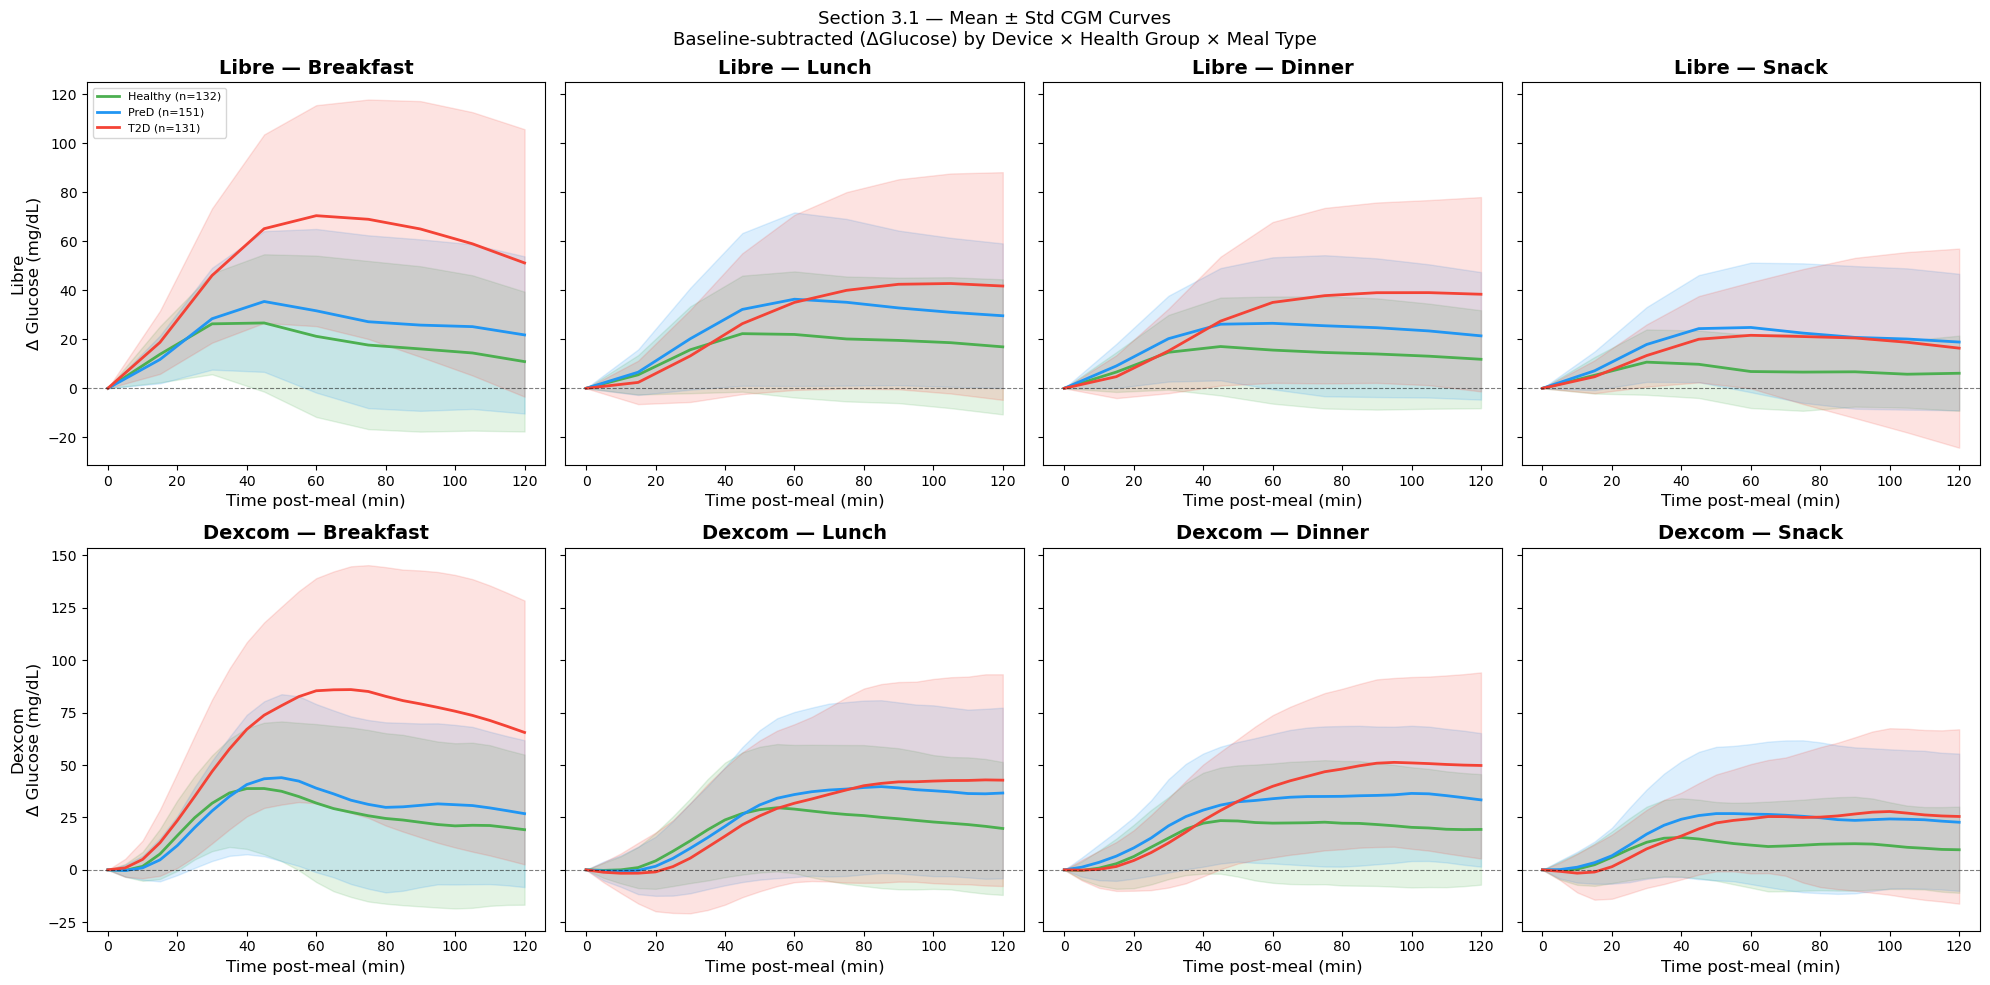

In [166]:
libre_times  = np.array([0, 15, 30, 45, 60, 75, 90, 105, 120])
dexcom_times = np.array([i*5 for i in range(25)])

def extract_matrix(df, trace_col, expected_len):
    """Stack traces into a 2D numpy matrix, baseline-subtracted (delta glucose)"""
    traces = []
    for t in df[trace_col]:
        if isinstance(t, list) and len(t) == expected_len:
            arr = np.array(t, dtype=float)
            if not np.any(np.isnan(arr)):
                traces.append(arr - arr[0])  # subtract baseline
    return np.array(traces) if traces else None

# 3.1 Average CGM curve by health group (both devices) 
fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharey='row')

meal_types = ['Breakfast', 'Lunch', 'Dinner', 'Snack']
groups     = ['Healthy', 'PreD', 'T2D']

for row, (device, trace_col, times, n_points, df) in enumerate([
    ('Libre',  'Libre_trace',  libre_times,  9,  meals_libre_df),
    ('Dexcom', 'Dexcom_trace', dexcom_times, 25, meals_dexcom_df),
]):
    for col, meal in enumerate(meal_types):
        ax     = axes[row, col]
        subset = df[df['Meal_Type'] == meal]

        for g in groups:
            gdf    = subset[subset['Health_group'] == g]
            matrix = extract_matrix(gdf, trace_col, n_points)
            if matrix is None or len(matrix) == 0:
                continue

            mean = matrix.mean(axis=0)
            std  = matrix.std(axis=0)
            n    = len(matrix)

            ax.plot(times, mean, color=HEALTH_COLORS[g],
                    linewidth=2, label=f"{g} (n={n})")
            ax.fill_between(times, mean-std, mean+std,
                            color=HEALTH_COLORS[g], alpha=0.15)

        ax.axhline(0, color='black', linestyle='--',
                   linewidth=0.8, alpha=0.5)
        ax.set_title(f"{device} — {meal}", fontweight='bold')
        ax.set_xlabel("Time post-meal (min)")
        if col == 0:
            ax.set_ylabel(f"{device}\nΔ Glucose (mg/dL)")
        if row == 0 and col == 0:
            ax.legend(fontsize=8)

plt.suptitle("Section 3.1 — Mean ± Std CGM Curves\n"
             "Baseline-subtracted (ΔGlucose) by Device × Health Group × Meal Type",
             fontsize=13)
plt.tight_layout()
plt.show()

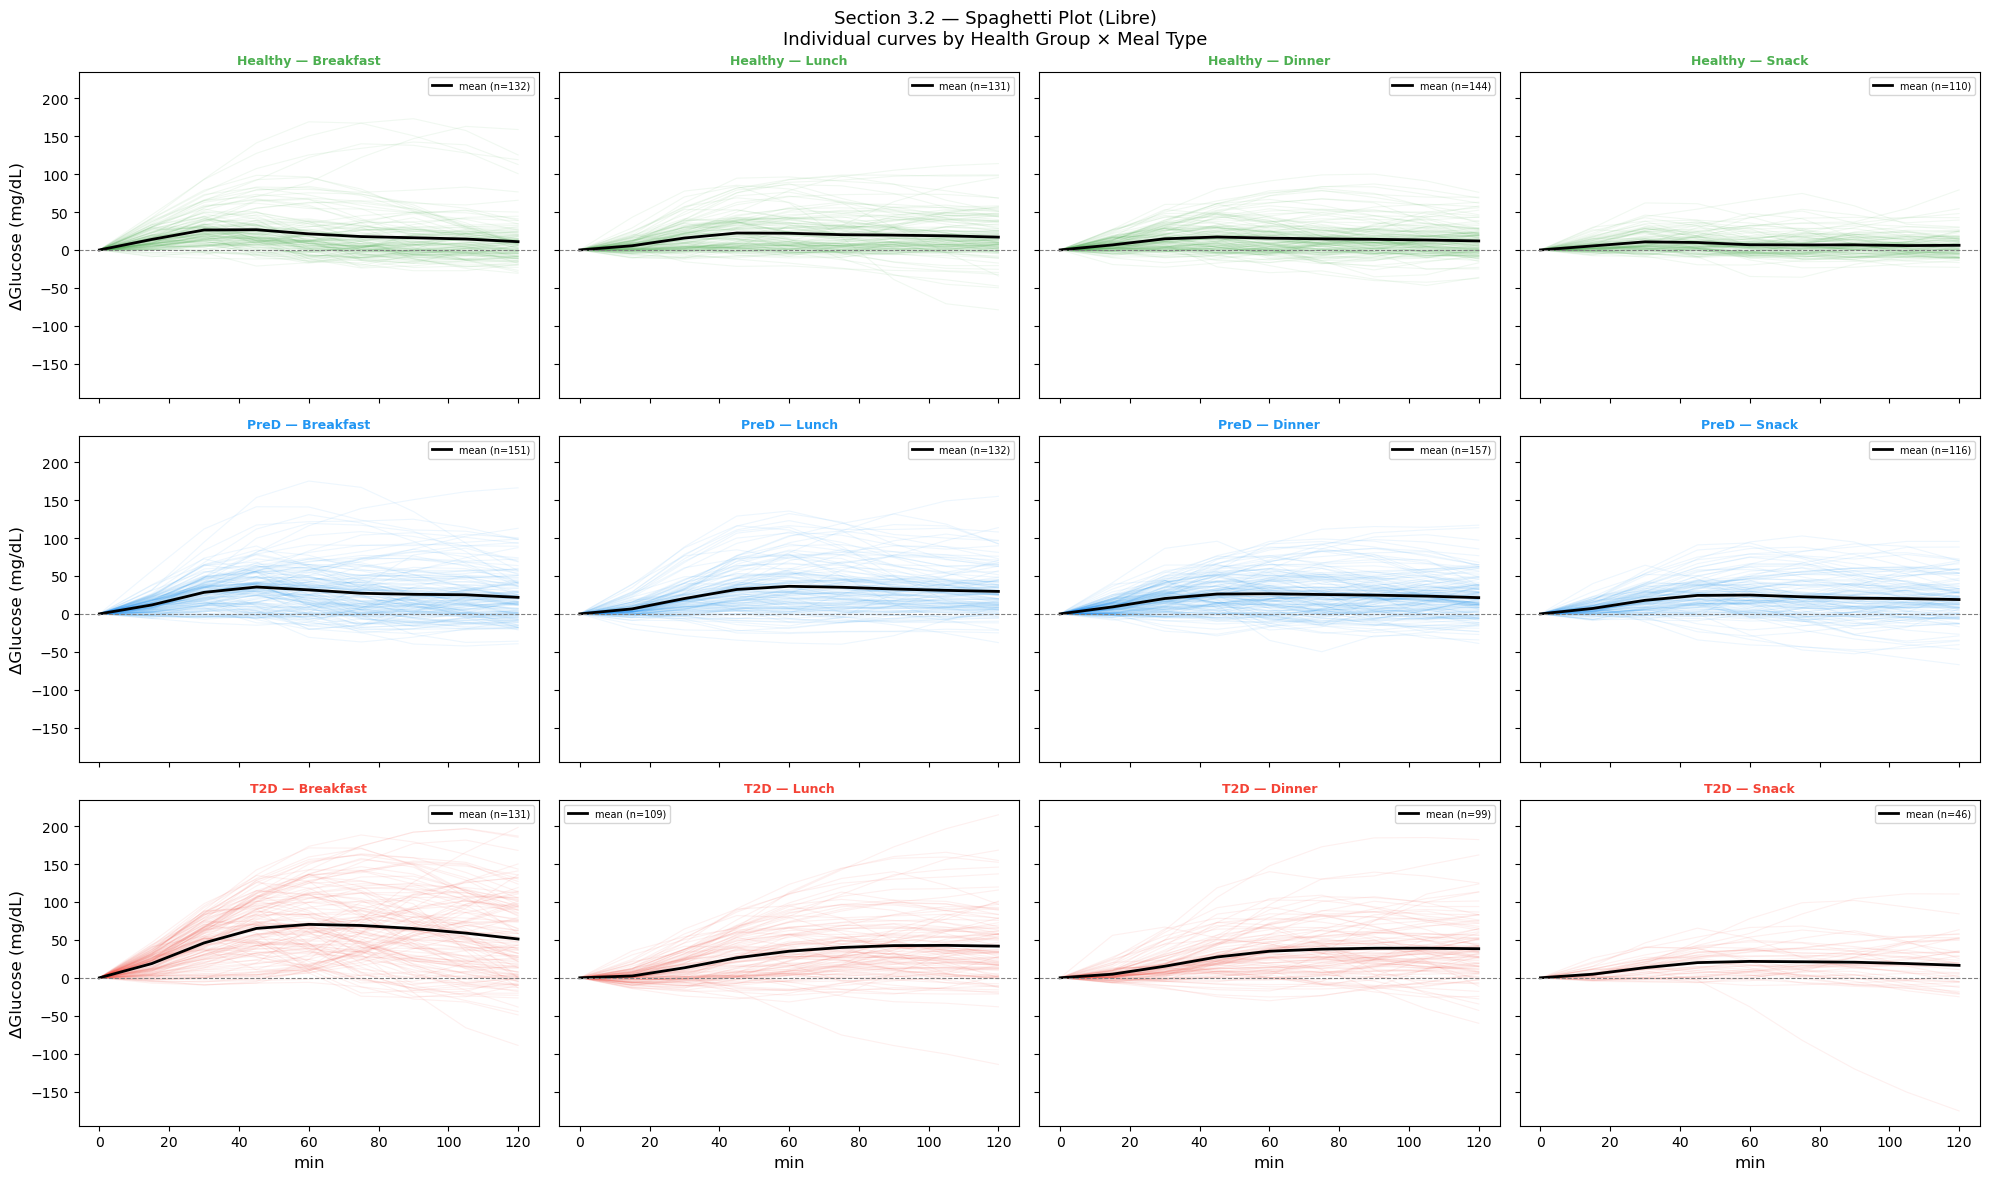

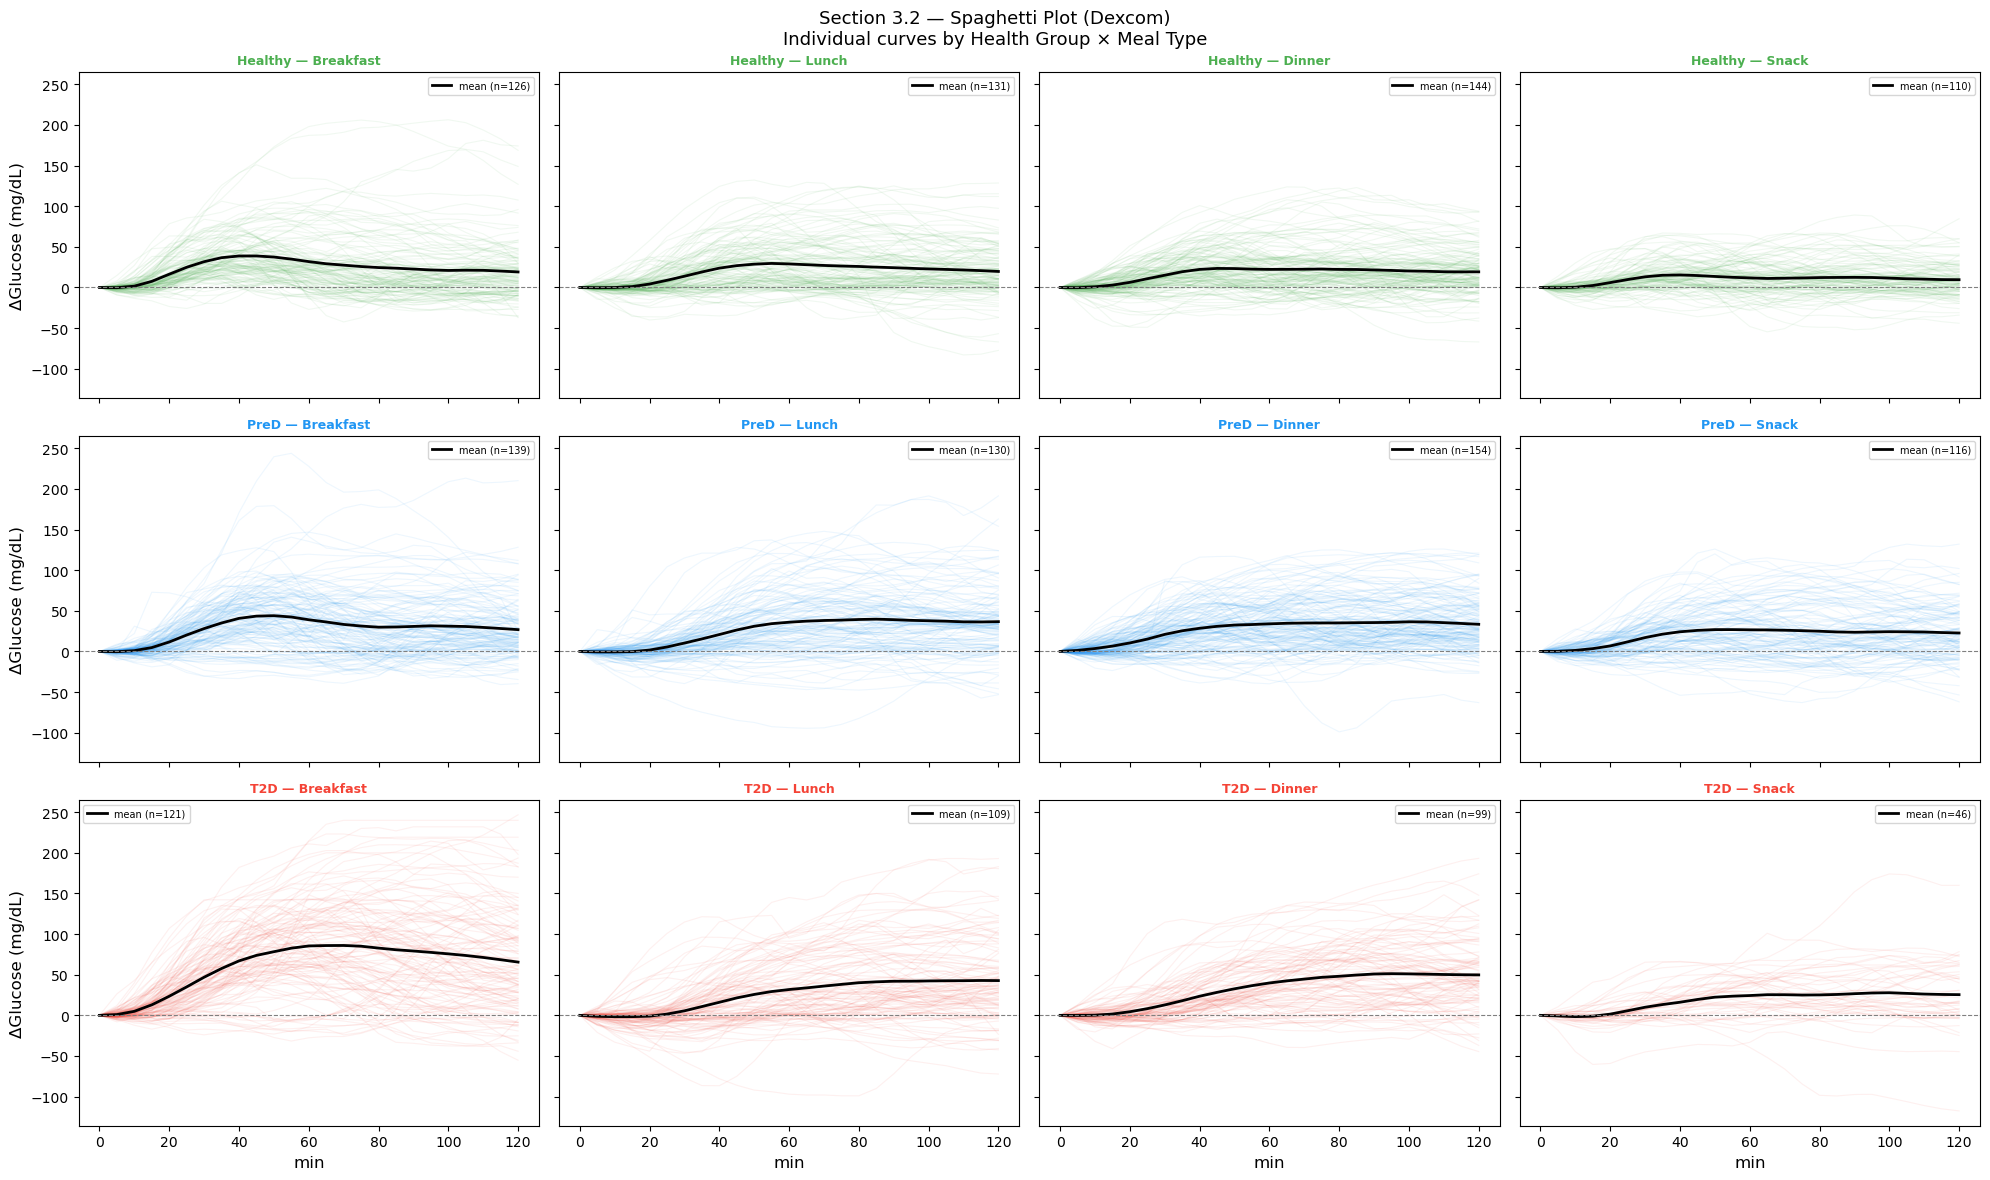

In [167]:
for device, trace_col, times, n_points, df in [
    ('Libre',  'Libre_trace',  libre_times,  9,  meals_libre_df),
    ('Dexcom', 'Dexcom_trace', dexcom_times, 25, meals_dexcom_df),
]:
    fig, axes = plt.subplots(3, 4, figsize=(20, 12),
                             sharey=True, sharex=True)

    for row, g in enumerate(groups):
        for col, meal in enumerate(meal_types):
            ax     = axes[row, col]
            subset = df[(df['Health_group'] == g) &
                        (df['Meal_Type']    == meal)]
            matrix = extract_matrix(subset, trace_col, n_points)

            if matrix is not None and len(matrix) > 0:
                # Individual curves — thin and transparent
                for trace in matrix:
                    ax.plot(times, trace,
                            color=HEALTH_COLORS[g],
                            alpha=0.08, linewidth=0.8)
                # Mean on top
                ax.plot(times, matrix.mean(axis=0),
                        color='black', linewidth=2,
                        label=f"mean (n={len(matrix)})")

            ax.axhline(0, color='gray', linestyle='--',
                       linewidth=0.8)
            ax.set_title(f"{g} — {meal}", fontsize=9,
                         color=HEALTH_COLORS[g], fontweight='bold')
            ax.set_xlabel("min" if row == 2 else "")
            if col == 0:
                ax.set_ylabel("ΔGlucose (mg/dL)")
            ax.legend(fontsize=7)

    plt.suptitle(f"Section 3.2 — Spaghetti Plot ({device})\n"
                 f"Individual curves by Health Group × Meal Type",
                 fontsize=13)
    plt.tight_layout()
    plt.show()